# Phase 4 – Court Judgment Prediction (CJPE) on the **GQLA** Phase-1 model

Decoder-only, causal Group-Query-Latent-Attention LM (10 layers, d=512, 64 query heads / 32 KV groups, latent KV 96) → binary outcome (0/1).

## What was wrong in the encoder-decoder notebook (and what changed here)

| # | Finding in `phase4_cjpe_experiments-2.ipynb` | Fix in this notebook |
|---|---|---|
| 1 | **Bug:** `BEST_REP` contained `method="frozen"` and was spread *after* `{"method": "full", ...}`, so B1–B7 (full FT, partial, gradual, LoRMA, adapter, KD, LoRA, rsLoRA, IA3 ...) all ran as the **frozen** model — identical numbers in every run, trainable params always 1.19M. | `REP` holds only representation keys; `run()` asserts `"method" not in REP` and asserts that non-frozen methods really have more trainable params than the head. |
| 2 | Training loss stayed ≈ ln 2 (0.69) in every run: the model never fit even the training set. Only 3 000 docs/epoch, batch of 1 document, random windows during training vs evenly spaced windows at inference. | Real mini-batches, fixed (deterministic) windows, class-weighted loss, ~10× more documents seen. |
| 3 | Your own keyword probe shows the outcome cue lives in the **tail** ("set aside" in the last 1 500 chars: 26 % of label-1 vs 8 % of label-0; head shows no signal) but 24 sliding windows dilute it. | Views like `"T0"`, `"T0,T1"`, `"H0,T0"`: only the windows that carry signal, ~5–10× cheaper per document. |
| 4 | Dev is 50/50 and has the same length profile as test; train is 41 % positive and shorter. Dev is the best proxy for test. | `DEV_HOLDOUT` docs of dev stay as clean validation (threshold + epoch selection); the rest of dev is added to training (`DEV_REPEAT`×). |
| 5 | Mean-pooling a causal encoder state dilutes keyword cues. | Per window: **last-token + mean + max** pooling (max-pool fires on cue words anywhere in the window). |
| 6 | GQLA has real biases (FFN + LayerNorm) so **true BitFit** is possible (the enc-dec model had none). | `bitfit` method added. |

## Honest expectations
I could **not** run this (no GPU / torch here). Torch-side code is untested; the pure-Python parts (windowing, metrics, threshold search, probe) are unit-tested. **0.7 is a target, not a guarantee.** Run Section 4 (CPU, ~minutes) first: it measures how much outcome signal a plain lexical model finds in each region of the document. That number tells you whether 0.7 is realistic *before* you spend GPU hours. That probe is a diagnostic only — it is not Phase-1 model output and must **not** be submitted (course rule: every submission must start from your Phase-1 model).

## Order of play (time is short: Phase 4 closes 21 Oct 23:59 IST)
1. Sections 1–5 (setup, data, tokenise, probe, load GQLA). 2. `benchmark()` → seq/s, then set `docs_per_epoch`. 3. `SMOKE_TEST` once. 4. B1 full FT first (it is also the KD teacher). 5. B2…B6, submit each zip; keep ≥6 *different techniques*.

> Course policy reminder (§17.5): LLM help is not allowed for hyperparameter tuning or for result analysis/conclusions, and the LLM declaration is mandatory. Declare the help you used for this notebook and be ready to explain every cell in the viva; write the analysis yourself.

## 1. Config

In [ ]:
import os, sys, re, json, random, unicodedata, zipfile, time, math, pickle, gc, copy
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED)
SMOKE_TEST = False          # True -> tiny subsets, 1 epoch; zips are NOT submittable

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = "/content/drive/MyDrive/Phase4_CJPE_GQLA"
else:
    OUTPUT_DIR = "./phase4_gqla_outputs"
if SMOKE_TEST: OUTPUT_DIR += "_smoke"
os.makedirs(OUTPUT_DIR, exist_ok=True)
DATA_DIR = "./phase4_cjpe_data"; os.makedirs(DATA_DIR, exist_ok=True)

# ---- EDIT: Phase-1 GQLA artefacts (paths from your Phase-1 notebook) ----
P1_DIR = "/content/drive/MyDrive/CS781/Capstone-Project/legal_dataset_cache"
CHECKPOINT_PATH = os.path.join(P1_DIR, "gqla_checkpoints", "gqla_baseline_large.pt")
TOKENIZER_PATH  = os.path.join(P1_DIR, "final_bpe_en.json")
# The GQLA checkpoint stores no config, so it is restated here (identical to your Phase-1 cell 44):
GQLA_CFG = dict(d_model=512, n_layers=10, num_query_heads=64, num_kv_groups=32, head_dim=64,
                kv_latent_dim=96, rope_dim=32, q_latent_dim=None, path="gqa")

# NEVER hard-code the HF token (your Phase-1 notebook has one in plain text -> revoke/rotate it). Use Colab secrets or env.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None and IN_COLAB:
    try:
        from google.colab import userdata; HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception: pass

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint as grad_checkpoint
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
if DEVICE.type == "cuda": torch.cuda.manual_seed_all(SEED); print("GPU:", torch.cuda.get_device_name(0))
print("Output dir:", OUTPUT_DIR, "| HF token set:", HF_TOKEN is not None, "| SMOKE_TEST:", SMOKE_TEST)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Output dir: /content/drive/MyDrive/Phase4_CJPE_GQLA | HF token set: True | SMOKE_TEST: False


## 2. Data, cleaning, metrics, logger, submission utilities

In [ ]:
from huggingface_hub import hf_hub_download
REPO_ID = "Exploration-Lab/CS-781-Capstone"
FILES = {"train": "Phase_4_CJPE/Train/train.json", "dev": "Phase_4_CJPE/Train/dev.json", "test": "Phase_4_CJPE/Test/test.json"}
raw_data = {}
for k, fn in FILES.items():
    p = hf_hub_download(repo_id=REPO_ID, filename=fn, repo_type="dataset", token=HF_TOKEN, local_dir=DATA_DIR)
    raw_data[k] = json.load(open(p, encoding="utf-8")); print(k, len(raw_data[k]))

def norm(x):
    s = unicodedata.normalize("NFKC", "" if x is None else str(x))
    return re.sub(r"\s+", " ", s.replace("\u00a0", " ")).strip()

def clean_split(raw, name, labeled):
    out = []
    for item in raw:
        rid = item["id"]; text = item["text"]
        if isinstance(text, (list, tuple)): text = " ".join(map(str, text))
        text = norm(text)
        if not text:
            if labeled: continue
            text = "."
        d = {"id": str(rid), "rid": rid, "text": text}
        if labeled:
            lab = item["label"]
            if isinstance(lab, (list, tuple)) and len(lab) == 1: lab = lab[0]
            lab = int(float(lab)); assert lab in (0, 1)
            d["label"] = lab
        out.append(d)
    return out

cleaned = {k: clean_split(raw_data[k], k, k != "test") for k in ["train", "dev", "test"]}
assert len(cleaned["test"]) == len(raw_data["test"]), "test docs dropped!"
assert len({d["id"] for d in cleaned["test"]}) == len(cleaned["test"]), "duplicate test ids"
print({k: len(v) for k, v in cleaned.items()})
for sp in ["train", "dev"]:
    c = Counter(d["label"] for d in cleaned[sp]); print(sp, dict(c), "frac_1 = %.3f" % (c[1] / sum(c.values())))

def cj_scores(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], average="macro", zero_division=0)
    _, _, fc, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], average=None, zero_division=0)
    return {"P": float(p), "R": float(r), "F1": float(f), "accuracy": float(np.mean(np.array(y_true) == np.array(y_pred))),
            "F1_c0": float(fc[0]), "F1_c1": float(fc[1])}

def tune_threshold(y_true, probs, grid=None):
    """Global threshold on P(1) maximising macro-F1; ties -> closest to 0.5."""
    grid = np.linspace(0.05, 0.95, 91) if grid is None else grid
    y_true, probs = np.asarray(y_true), np.asarray(probs)
    best_t, best_f = 0.5, -1.0
    for t in grid:
        f = cj_scores(y_true, (probs >= t).astype(int))["F1"]
        if f > best_f + 1e-12 or (abs(f - best_f) <= 1e-12 and abs(t - 0.5) < abs(best_t - 0.5)): best_t, best_f = float(t), f
    return best_t, best_f

def plot_confusion(y_true, y_pred, title, path=None):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1]); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(3.6, 3.2)); ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2): ax.text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.2f})", ha="center", va="center", fontsize=8)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title(title, fontsize=8)
    plt.tight_layout()
    if path: plt.savefig(path, dpi=150)
    plt.show()

REGISTRY_PATH = os.path.join(OUTPUT_DIR, "experiment_registry.csv")
registry = pd.read_csv(REGISTRY_PATH).to_dict("records") if os.path.exists(REGISTRY_PATH) else []
def log_experiment(name, technique, trainable, total, scores, extra):
    row = {"name": name, "technique": technique, "trainable_params": trainable, "total_params": total, **extra,
           "time": time.strftime("%Y-%m-%d %H:%M")}
    row.update({k: round(v, 4) if isinstance(v, float) else v for k, v in scores.items()})
    registry.append(row); pd.DataFrame(registry).to_csv(REGISTRY_PATH, index=False); return row

def build_submission(docs, probs, thr):
    return [{"id": d["rid"], "pred": int(probs[d["id"]] >= thr)} for d in docs]

def validate_submission(sub):
    expected = [str(d["rid"]) for d in cleaned["test"]]; got = [str(x["id"]) for x in sub]
    assert isinstance(sub, list) and len(got) == len(set(got)), "not a list / duplicate ids"
    assert not (set(expected) - set(got)), "missing ids"; assert not (set(got) - set(expected)), "unknown ids"
    for x in sub:
        assert set(x) == {"id", "pred"} and type(x["pred"]) is int and x["pred"] in (0, 1), x
    return True

def package_submission(sub, zip_path):
    validate_submission(sub)
    jp = os.path.join(os.path.dirname(zip_path), "prediction.json")
    json.dump(sub, open(jp, "w", encoding="utf-8"), ensure_ascii=False)
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z: z.write(jp, arcname="prediction.json")
    with zipfile.ZipFile(zip_path) as z: assert z.namelist() == ["prediction.json"]
    return zip_path

train 37387
dev 1988
test 1517
{'train': 37387, 'dev': 1988, 'test': 1517}
train {0: 22067, 1: 15320} frac_1 = 0.410
dev {0: 994, 1: 994} frac_1 = 0.500


## 3. Phase-1 tokenizer and tokenisation (documents are trimmed to first 2 048 + last 6 144 tokens: the tail is what matters)

In [ ]:
import os
import re
import json
import heapq
import collections

try:
    import psutil
    _PROC = psutil.Process(os.getpid())
except Exception:                       # psutil optional
    _PROC = None


def _ram_gb():
    return _PROC.memory_info().rss / (1024 ** 3) if _PROC else 0.0


# ============================================================
# MUST BE IDENTICAL FOR TRAINING AND INFERENCE
# ============================================================
WORD_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)


# ---- multiprocessing helpers (module level so they can be pickled) ----
_WORKER = None

def _init_worker(tok):
    global _WORKER
    _WORKER = tok

def _encode_chunk(args):
    texts, add_special = args
    return [_WORKER.encode(t, add_special) for t in texts]


class BPETokenizer:

    _HEAP_THRESHOLD = 24        # words longer than this use the heap merger
    _CACHE_LIMIT = 500_000

    # ========================================================
    # INIT
    # ========================================================
    def __init__(self, vocab_size, end_marker="</w>", reserved_tokens=None):
        self.vocab_size = vocab_size
        self.end_marker = end_marker
        self.reserved_tokens = (
            reserved_tokens
            if reserved_tokens is not None
            else ["<pad>", "<unk>", "<s>", "</s>"]
        )

        self.itos = list(self.reserved_tokens)
        self.stoi = {t: i for i, t in enumerate(self.reserved_tokens)}

        # (id_a, id_b) -> merge rank. Rank r created token first_merge_id + r.
        self.merges = {}

        self._ready = False
        self._cache = {}

    # ========================================================
    # SAVE / LOAD
    # ========================================================
    def save(self, path):
        data = {
            "vocab_size": self.vocab_size,
            "end_marker": self.end_marker,
            "reserved_tokens": self.reserved_tokens,
            "itos": self.itos,
            "stoi": self.stoi,
            "merges": [[list(p), r] for p, r in self.merges.items()],
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False)   # no indent: much smaller/faster

        print(f"Tokenizer saved to: {path}")
        print(f"Vocabulary size: {len(self.itos):,}")
        print(f"Number of merges: {len(self.merges):,}")

    @staticmethod
    def from_json(path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        tok = BPETokenizer(
            vocab_size=data["vocab_size"],
            end_marker=data.get("end_marker", "</w>"),
            reserved_tokens=data.get(
                "reserved_tokens", ["<pad>", "<unk>", "<s>", "</s>"]
            ),
        )
        tok.itos = data["itos"]
        tok.stoi = data["stoi"]
        tok.merges = {tuple(p): r for p, r in data["merges"]}
        tok._ready = False
        tok._cache = {}
        return tok

    # ========================================================
    # BASE VOCAB
    # ========================================================
    def _initialize_bytes(self):
        """Reserved tokens, then 256 byte tokens, then </w>."""
        for b in range(256):
            tok = bytes([b]).decode("latin-1")
            if tok not in self.stoi:
                self.stoi[tok] = len(self.itos)
                self.itos.append(tok)

        if self.end_marker not in self.stoi:
            self.stoi[self.end_marker] = len(self.itos)
            self.itos.append(self.end_marker)

    # ========================================================
    # WORD FREQUENCIES  (memory-safe)
    # ========================================================
    def _get_initial_vocab(
        self,
        corpus_texts,
        max_examples=200_000,
        prune_every=5_000,
        prune_threshold=2,
        max_unique_words=2_000_000,
        max_doc_chars=500_000,
    ):
        """
        Count words as plain strings (far lighter than tuples of ints),
        periodically dropping the long tail (typos, ids, citation numbers),
        with a hard cap on the number of unique words. Only the survivors are
        converted to byte-id tuples.

        Dropped rare words are still encodable at inference through byte
        fallback, so this costs almost nothing in tokenizer quality.
        """
        self._initialize_bytes()
        end_id = self.stoi[self.end_marker]

        counts = collections.Counter()
        threshold = prune_threshold
        n = 0
        last_ram = _ram_gb()

        def prune(th):
            return collections.Counter(
                {w: c for w, c in counts.items() if c >= th}
            )

        for n, text in enumerate(corpus_texts, 1):
            if not isinstance(text, str):
                continue

            if len(text) > max_doc_chars:
                print(
                    f"  [warn] example {n:,} has {len(text):,} chars "
                    f"-> truncated to {max_doc_chars:,}"
                )
                text = text[:max_doc_chars]

            # generator: never builds a giant list of words in memory
            counts.update(m.group() for m in WORD_RE.finditer(text))

            if n % 100 == 0:
                ram = _ram_gb()
                if ram - last_ram > 0.3:
                    print(f"  [warn] RAM jumped {last_ram:.2f} -> {ram:.2f} GB near example {n:,}")
                last_ram = ram

            if n % prune_every == 0:
                counts = prune(threshold)

            # hard safety cap: raise threshold until we fit
            while len(counts) > max_unique_words:
                threshold += 1
                counts = prune(threshold)
                print(f"  cap hit -> prune threshold raised to {threshold}")

            if n % 1000 == 0:
                print(
                    f"Examples: {n:,} | Unique words: {len(counts):,} "
                    f"| RAM: {_ram_gb():.2f} GB"
                )

            if n >= max_examples:
                break

        counts = prune(prune_threshold)     # final prune

        # convert survivors to id tuples
        byte_ids = [self.stoi[bytes([b]).decode("latin-1")] for b in range(256)]
        word_freqs = {}
        for w, c in counts.items():
            ids = tuple(byte_ids[b] for b in w.encode("utf-8")) + (end_id,)
            word_freqs[ids] = word_freqs.get(ids, 0) + c
        del counts

        print(f"\nFinished reading corpus. Examples: {n:,}")
        print(f"Unique words kept: {len(word_freqs):,}")
        return word_freqs

    # ========================================================
    # TRAIN
    # ========================================================
    def train(
        self,
        corpus_texts,
        save_checkpoints=None,
        checkpoint_dir=None,
        max_examples=200_000,
        prune_every=5_000,
        prune_threshold=2,
        max_unique_words=2_000_000,
        max_doc_chars=500_000,
    ):
        save_checkpoints = set(save_checkpoints or [])
        checkpoint_dir = checkpoint_dir or "."
        os.makedirs(checkpoint_dir, exist_ok=True)

        # ---- Step 1: word frequencies --------------------------------
        print("\nSTEP 1: word frequencies")
        word_freqs = self._get_initial_vocab(
            corpus_texts,
            max_examples=max_examples,
            prune_every=prune_every,
            prune_threshold=prune_threshold,
            max_unique_words=max_unique_words,
            max_doc_chars=max_doc_chars,
        )

        words = [list(w) for w in word_freqs]
        freqs = list(word_freqs.values())
        del word_freqs

        # ---- Step 2: pair statistics ---------------------------------
        print("\nSTEP 2: pair statistics")
        pair_counts = collections.defaultdict(int)
        pair_to_words = collections.defaultdict(set)     # pair -> word indices

        for idx, (w, f) in enumerate(zip(words, freqs)):
            for pair in zip(w, w[1:]):
                pair_counts[pair] += f
                pair_to_words[pair].add(idx)

        heap = [(-c, p) for p, c in pair_counts.items()]
        heapq.heapify(heap)

        print(f"Initial vocab size: {len(self.itos):,}")
        print(f"Unique words:       {len(words):,}")
        print(f"Unique pairs:       {len(pair_counts):,}")
        print(f"RAM: {_ram_gb():.2f} GB")

        # ---- Step 3: merges ------------------------------------------
        print("\nSTEP 3: BPE merges")

        while len(self.itos) < self.vocab_size:

            # pop until an up-to-date entry is found (lazy deletion)
            best_pair, best_freq = None, 0
            while heap:
                neg, pair = heapq.heappop(heap)
                if -neg > 0 and pair_counts.get(pair, 0) == -neg:
                    best_pair, best_freq = pair, -neg
                    break

            if best_pair is None:
                print("No more pairs available.")
                break

            a, b = best_pair

            new_id = len(self.itos)
            new_str = self.itos[a] + self.itos[b]
            self.itos.append(new_str)
            self.stoi.setdefault(new_str, new_id)
            self.merges[best_pair] = len(self.merges)

            affected = pair_to_words.pop(best_pair, set())
            changed = set()

            for idx in affected:
                w, f = words[idx], freqs[idx]

                for p in zip(w, w[1:]):
                    pair_counts[p] -= f
                    changed.add(p)
                    if p != best_pair:
                        s = pair_to_words.get(p)
                        if s is not None:
                            s.discard(idx)

                out, i, n = [], 0, len(w)
                while i < n:
                    if i < n - 1 and w[i] == a and w[i + 1] == b:
                        out.append(new_id)
                        i += 2
                    else:
                        out.append(w[i])
                        i += 1
                words[idx] = out

                for p in zip(out, out[1:]):
                    pair_counts[p] += f
                    pair_to_words[p].add(idx)
                    changed.add(p)

            pair_counts.pop(best_pair, None)
            changed.discard(best_pair)

            for p in changed:
                c = pair_counts.get(p, 0)
                if c > 0:
                    heapq.heappush(heap, (-c, p))
                else:
                    pair_counts.pop(p, None)
                    pair_to_words.pop(p, None)

            # rebuild heap if it is mostly stale (bounds heap memory)
            if len(heap) > 4 * len(pair_counts) + 10_000:
                heap = [(-c, p) for p, c in pair_counts.items()]
                heapq.heapify(heap)

            vocab_now = len(self.itos)

            if vocab_now % 1000 == 0:
                print(
                    f"Vocab: {vocab_now:,} | merge freq: {best_freq:,} | "
                    f"affected: {len(affected):,} | pairs: {len(pair_counts):,} "
                    f"| RAM: {_ram_gb():.2f} GB"
                )

            if vocab_now in save_checkpoints:
                self.save(os.path.join(checkpoint_dir, f"bpe_{vocab_now}-large.json"))

        self._ready = False
        self._cache = {}

        print("\nBPE training complete.")
        print(f"Final vocabulary size: {len(self.itos):,}")
        print(f"Merges learned:        {len(self.merges):,}")

    # ========================================================
    # INFERENCE SETUP
    # ========================================================
    def _prepare_inference(self):
        if self._ready:
            return

        self._byte_ids = [
            self.stoi[bytes([b]).decode("latin-1")] for b in range(256)
        ]
        self._first_merge_id = len(self.itos) - len(self.merges)
        self._end_id = self.stoi.get(self.end_marker, self.stoi["<unk>"])
        self._bos = self.stoi["<s>"]
        self._eos = self.stoi["</s>"]

        # sanity check: rank r must have created token first_merge_id + r
        base = self._first_merge_id
        for (a, b), r in self.merges.items():
            if self.itos[base + r] != self.itos[a] + self.itos[b]:
                raise ValueError(
                    "Merge/vocab mismatch: cannot infer merge ids from ranks."
                )

        # integer keys: faster than tuple keys
        self._M = len(self.itos)
        M = self._M
        self._ranks = {a * M + b: r for (a, b), r in self.merges.items()}

        self._cache = {}
        self._ready = True

    # ========================================================
    # MERGE STRATEGIES
    # ========================================================
    def _merge_small(self, ids):
        """Repeated best-rank scan. Fastest for short words."""
        get, M, base = self._ranks.get, self._M, self._first_merge_id

        while len(ids) > 1:
            best, best_i = None, -1
            for i in range(len(ids) - 1):
                r = get(ids[i] * M + ids[i + 1])
                if r is not None and (best is None or r < best):
                    best, best_i = r, i

            if best is None:
                break

            a, b, new = ids[best_i], ids[best_i + 1], base + best
            out, i, n = [], 0, len(ids)
            while i < n:
                if i < n - 1 and ids[i] == a and ids[i + 1] == b:
                    out.append(new)
                    i += 2
                else:
                    out.append(ids[i])
                    i += 1
            ids = out

        return ids

    def _merge_heap(self, ids):
        """Linked list + min-heap: O(n log n) for long words."""
        get, M, base = self._ranks.get, self._M, self._first_merge_id

        n = len(ids)
        nxt = list(range(1, n + 1))
        nxt[-1] = -1
        prv = list(range(-1, n - 1))
        alive = [True] * n

        heap = []
        for i in range(n - 1):
            r = get(ids[i] * M + ids[i + 1])
            if r is not None:
                heap.append((r, i))
        heapq.heapify(heap)

        while heap:
            r, i = heapq.heappop(heap)
            if not alive[i]:
                continue
            j = nxt[i]
            if j == -1 or get(ids[i] * M + ids[j]) != r:
                continue                        # stale entry

            ids[i] = base + r
            alive[j] = False
            k = nxt[j]
            nxt[i] = k
            if k != -1:
                prv[k] = i

            p = prv[i]
            if p != -1:
                r2 = get(ids[p] * M + ids[i])
                if r2 is not None:
                    heapq.heappush(heap, (r2, p))
            if k != -1:
                r2 = get(ids[i] * M + ids[k])
                if r2 is not None:
                    heapq.heappush(heap, (r2, i))

        return [ids[i] for i in range(n) if alive[i]]

    def _bpe_word(self, word):
        hit = self._cache.get(word)
        if hit is not None:
            return hit

        ids = [self._byte_ids[b] for b in word.encode("utf-8")]
        ids.append(self._end_id)

        if len(ids) <= self._HEAP_THRESHOLD:
            ids = self._merge_small(ids)
        else:
            ids = self._merge_heap(ids)

        result = tuple(ids)
        if len(self._cache) < self._CACHE_LIMIT:
            self._cache[word] = result
        return result

    # ========================================================
    # PUBLIC API
    # ========================================================
    def encode(self, text, add_special_tokens=True):
        """Fast path: token ids only."""
        self._prepare_inference()

        out = [self._bos] if add_special_tokens else []
        extend = out.extend
        cache_get = self._cache.get
        bpe = self._bpe_word

        for w in WORD_RE.findall(text):
            t = cache_get(w)
            if t is None:
                t = bpe(w)
            extend(t)

        if add_special_tokens:
            out.append(self._eos)
        return out

    def tokenize(self, text, add_special_tokens=True):
        """Returns (token_ids, token_strings). Use encode() for bulk work."""
        ids = self.encode(text, add_special_tokens)
        itos = self.itos
        return ids, [itos[i] for i in ids]

    def encode_batch(self, texts, add_special_tokens=True,
                     num_workers=None, chunk_size=256):
        """Encode many documents, optionally across processes (fork only)."""
        self._prepare_inference()
        texts = list(texts)

        if num_workers is None:
            num_workers = os.cpu_count() or 1

        if num_workers <= 1 or len(texts) < 2 * chunk_size:
            return [self.encode(t, add_special_tokens) for t in texts]

        import multiprocessing as mp
        chunks = [
            (texts[i:i + chunk_size], add_special_tokens)
            for i in range(0, len(texts), chunk_size)
        ]
        ctx = mp.get_context("fork")
        with ctx.Pool(num_workers, initializer=_init_worker,
                      initargs=(self,)) as pool:
            results = list(pool.imap(_encode_chunk, chunks))
        return [ids for chunk in results for ids in chunk]

    def decode(self, token_ids):
        """Decodes a list of token IDs back into a string, handling special tokens."""
        self._prepare_inference()
        # Filter out special tokens for a cleaner decoded string
        filtered_ids = [
            tid for tid in token_ids
            if self.itos[tid] not in self.reserved_tokens
        ]
        # Join the token strings, replacing </w> with a space
        decoded_text = "".join([self.itos[tid] for tid in filtered_ids]).replace(self.end_marker, " ")
        return decoded_text.strip()


if not os.path.isfile(TOKENIZER_PATH): raise FileNotFoundError(TOKENIZER_PATH)
tokenizer = BPETokenizer.from_json(TOKENIZER_PATH)
PAD_ID = tokenizer.stoi.get("<pad>", 0); BOS_ID = tokenizer.stoi.get("<s>", 2); EOS_ID = tokenizer.stoi.get("</s>", 3)
VOCAB_SIZE = len(tokenizer.itos)
print("vocab", VOCAB_SIZE, "| PAD/BOS/EOS", PAD_ID, BOS_ID, EOS_ID)

vocab 32768 | PAD/BOS/EOS 0 2 3


In [ ]:
KEEP_HEAD, KEEP_TAIL, MAX_CHARS = 2048, 6144, 120_000
CACHE_PATH = os.path.join(OUTPUT_DIR, "tok_cache_gqla.pkl")
cache = pickle.load(open(CACHE_PATH, "rb")) if os.path.exists(CACHE_PATH) else {}

def trim_ht(x, head, tail):
    return x if len(x) <= head + tail else x[:head] + x[-tail:]

def tokenise_split(name, docs):
    sig = [d["id"] for d in docs]; c = cache.get(name)
    if c and c["sig"] == sig and c["cfg"] == (KEEP_HEAD, KEEP_TAIL, MAX_CHARS, VOCAB_SIZE): return c["arrays"]
    arrays, t0 = [], time.time()
    for s in range(0, len(docs), 256):
        texts = [t if len(t) <= MAX_CHARS else t[:MAX_CHARS // 4] + t[-(MAX_CHARS - MAX_CHARS // 4):] for t in (d["text"] for d in docs[s:s + 256])]
        ids = tokenizer.encode_batch(texts, add_special_tokens=False, chunk_size=8)
        arrays += [np.asarray(trim_ht(x, KEEP_HEAD, KEEP_TAIL), dtype=np.int32) for x in ids]
        print(f"  {name}: {len(arrays)}/{len(docs)} ({time.time()-t0:.0f}s)", end="\r")
    print(); cache[name] = {"sig": sig, "cfg": (KEEP_HEAD, KEEP_TAIL, MAX_CHARS, VOCAB_SIZE), "arrays": arrays}
    pickle.dump(cache, open(CACHE_PATH, "wb")); return arrays

if SMOKE_TEST:
    rs = random.Random(SEED)
    cleaned["train"] = rs.sample(cleaned["train"], 96); cleaned["dev"] = rs.sample(cleaned["dev"], 48); cleaned["test"] = cleaned["test"][:16]
for sp in ["train", "dev", "test"]:
    for d, a in zip(cleaned[sp], tokenise_split(sp, cleaned[sp])): d["ids"], d["n_tok"] = a, len(a)
    for d in cleaned[sp]: d["text"] = None          # free RAM
    n = pd.Series([d["n_tok"] for d in cleaned[sp]])
    print(sp, "tokens/doc", n.describe(percentiles=[.25, .5, .75, .95]).round(0).to_dict())

# dev -> clean validation hold-out (stratified) + extra training data (dev is closer to test than train is)
DEV_HOLDOUT, DEV_REPEAT = (24 if SMOKE_TEST else 1000), 3
rs = random.Random(SEED); by = defaultdict(list)
for d in cleaned["dev"]: by[d["label"]].append(d)
dev_val = []
for lab, ds in by.items(): dev_val += rs.sample(ds, round(DEV_HOLDOUT * len(ds) / len(cleaned["dev"])))
_vid = {d["id"] for d in dev_val}
DATA = {"train": cleaned["train"], "dev_full": cleaned["dev"], "dev_val": dev_val,
        "dev_train": [d for d in cleaned["dev"] if d["id"] not in _vid], "test": cleaned["test"]}
print({k: len(v) for k, v in DATA.items()})

  train: 37387/37387 (181s)
train tokens/doc {'count': 37387.0, 'mean': 3282.0, 'std': 2460.0, 'min': 53.0, '25%': 1287.0, '50%': 2689.0, '75%': 4759.0, '95%': 8192.0, 'max': 8192.0}
  dev: 1988/1988 (11s)
dev tokens/doc {'count': 1988.0, 'mean': 4016.0, 'std': 2256.0, 'min': 190.0, '25%': 2196.0, '50%': 3469.0, '75%': 5554.0, '95%': 8192.0, 'max': 8192.0}
  test: 1517/1517 (8s)
test tokens/doc {'count': 1517.0, 'mean': 4088.0, 'std': 2279.0, 'min': 96.0, '25%': 2281.0, '50%': 3579.0, '75%': 5649.0, '95%': 8192.0, 'max': 8192.0}
{'train': 37387, 'dev_full': 1988, 'dev_val': 1000, 'dev_train': 464, 'test': 1517}


## 4. CPU diagnostic – *where in a judgment is the outcome signal?* (not a submission)
Bag of token-id unigrams + hashed bigrams → TF-IDF → logistic regression, one region at a time, scored on `dev_val`.
It tells you (a) which windows are worth feeding the GQLA model and (b) a rough lexical reference level. Interpret it yourself.

In [ ]:
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.linear_model import LogisticRegression
NB = 1 << 20
def region_ids(d, region):
    a, n = d["ids"], d["n_tok"]
    if region == "head512": return a[:512]
    if region.startswith("tail"):
        k = int(region[4:]); return a[max(0, n - k):]
    if region == "T1_512": return a[max(0, n - 1024): max(0, n - 512)]
    if region == "T2_512": return a[max(0, n - 1536): max(0, n - 1024)]
    if region == "middle": return a[n // 2 - 256: n // 2 + 256]
    if region == "whole": return a
    raise ValueError(region)
def bow(docs, region):
    rows, cols, vals = [], [], []
    for i, d in enumerate(docs):
        x = region_ids(d, region).astype(np.int64)
        feats = np.concatenate([x, (x[:-1] * 32768 + x[1:]) % NB + 32768]) if len(x) > 1 else x
        u, c = np.unique(feats, return_counts=True); rows += [i] * len(u); cols += u.tolist(); vals += c.tolist()
    return sp.csr_matrix((vals, (rows, cols)), shape=(len(docs), NB + 32768), dtype=np.float32)
def lexical_probe(regions, n_train=20000):
    tr = random.Random(SEED).sample(DATA["train"], min(n_train, len(DATA["train"]))); va = DATA["dev_val"]
    ytr, yva = [d["label"] for d in tr], [d["label"] for d in va]; rows = []
    for r in regions:
        Xtr, Xva = bow(tr, r), bow(va, r); tf = TfidfTransformer(sublinear_tf=True).fit(Xtr)
        lr = LogisticRegression(C=2.0, max_iter=300, class_weight="balanced").fit(tf.transform(Xtr), ytr)
        p = lr.predict_proba(tf.transform(Xva))[:, 1]; sc = cj_scores(yva, (p >= 0.5).astype(int))
        rows.append({"region": r, "F1@0.5": round(sc["F1"], 4), "F1_tuned": round(tune_threshold(yva, p)[1], 4)}); print(rows[-1])
    return pd.DataFrame(rows)
probe_df = lexical_probe(["head512", "middle", "tail256", "tail512", "T1_512", "T2_512", "tail1024", "whole"] if not SMOKE_TEST else ["tail512"])
probe_df

{'region': 'head512', 'F1@0.5': 0.4885, 'F1_tuned': 0.543}
{'region': 'middle', 'F1@0.5': 0.5431, 'F1_tuned': 0.5644}
{'region': 'tail256', 'F1@0.5': 0.5884, 'F1_tuned': 0.6172}
{'region': 'tail512', 'F1@0.5': 0.5836, 'F1_tuned': 0.6305}
{'region': 'T1_512', 'F1@0.5': 0.5879, 'F1_tuned': 0.5879}
{'region': 'T2_512', 'F1@0.5': 0.5666, 'F1_tuned': 0.5702}
{'region': 'tail1024', 'F1@0.5': 0.62, 'F1_tuned': 0.6547}
{'region': 'whole', 'F1@0.5': 0.6185, 'F1_tuned': 0.6439}


,region,F1@0.5,F1_tuned
0,head512,0.4885,0.5430
1,middle,0.5431,0.5644
2,tail256,0.5884,0.6172
3,tail512,0.5836,0.6305
4,T1_512,0.5879,0.5879
5,T2_512,0.5666,0.5702
6,tail1024,0.6200,0.6547
7,whole,0.6185,0.6439


## 5. Load the Phase-1 GQLA model (classes copied verbatim from your Phase-1 notebook)

In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# RoPE
# ============================================================

class GQLARotaryEmbedding(nn.Module):
    """
    Rotary embedding used only on the decoupled RoPE pathway.

    GQLA:
        q^R_t = RoPE_t(W_QR c^Q_t)
        k^R_t = RoPE_t(W_KR x_t)

    Input:
        x:
            [B, H, T, rope_dim]

        position_ids:
            [B, T]
    """

    def __init__(
        self,
        dim: int,
        base: float = 10000.0,
    ):
        super().__init__()

        if dim % 2 != 0:
            raise ValueError(
                f"RoPE dimension must be even, got {dim}"
            )

        self.dim = dim
        self.base = base

        inv_freq = 1.0 / (
            base ** (
                torch.arange(
                    0,
                    dim,
                    2,
                    dtype=torch.float32
                ) / dim
            )
        )

        self.register_buffer(
            "inv_freq",
            inv_freq,
            persistent=False
        )

    @staticmethod
    def rotate_half(x):
        half = x.shape[-1] // 2

        x1 = x[..., :half]
        x2 = x[..., half:]

        return torch.cat(
            [-x2, x1],
            dim=-1
        )

    def forward(
        self,
        x,
        position_ids,
    ):
        """
        x:
            [B, H, T, dim]

        position_ids:
            [B, T]
        """
        # [B, T, dim/2]
        freqs = torch.einsum(
            "bt,d->btd",
            position_ids.float(),
            self.inv_freq
        )

        # [B, T, dim]
        emb = torch.cat(
            [freqs, freqs],
            dim=-1
        )

        cos = emb.cos().unsqueeze(1)
        sin = emb.sin().unsqueeze(1)

        x_rope = x[..., :self.dim]

        x_rope = (
            x_rope * cos
            + self.rotate_half(x_rope) * sin
        )

        return x_rope

In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# GQLA
# ============================================================

class GroupQueryLatentAttention(nn.Module):

    def __init__(
        self,
        d_model: int,
        num_query_heads: int,
        num_kv_groups: int,
        head_dim: int,
        kv_latent_dim: int,
        rope_dim: int,
        q_latent_dim: int = None,
        dropout: float = 0.1,
        rope_base: float = 10000.0,
        path: str = "gqa",
    ):
        super().__init__()

        if num_query_heads % num_kv_groups != 0:
            raise ValueError(
                "num_query_heads must be divisible by "
                "num_kv_groups"
            )

        if path not in {"gqa", "mqa_absorb"}:
            raise ValueError(
                "path must be either 'gqa' or 'mqa_absorb'"
            )

        self.d_model = d_model
        self.num_query_heads = num_query_heads
        self.num_kv_groups = num_kv_groups
        self.head_dim = head_dim

        self.kv_latent_dim = kv_latent_dim
        self.rope_dim = rope_dim
        self.path = path # Add this line to store the path as an instance attribute

        self.heads_per_group = (
            num_query_heads // num_kv_groups
        )

        # ----------------------------------------------------
        # Q-side latent
        #
        # c_Q = W_DQ x
        # q_C = W_UQ c_Q
        # ----------------------------------------------------

        if q_latent_dim is None:
            # Paper explicitly notes that for models such as
            # LLaMA-3-8B and Qwen2.5-7B this factorization
            # collapses to W_Q directly.
            q_latent_dim = d_model

        self.q_latent_dim = q_latent_dim

        self.W_DQ = nn.Linear(
            d_model,
            q_latent_dim,
            bias=False
        )

        self.W_UQ = nn.Linear(
            q_latent_dim,
            num_query_heads * head_dim,
            bias=False
        )

        # ----------------------------------------------------
        # KV latent
        #
        # c_KV = W_DKV x
        # ----------------------------------------------------

        self.W_DKV = nn.Linear(
            d_model,
            kv_latent_dim,
            bias=False
        )

        # ----------------------------------------------------
        # GROUP indexed up-projections
        #
        # W_UK, W_UV:
        #
        # [g * d_h, r_KV]
        #
        # NOT:
        #
        # [h_q * d_h, r_KV]
        #
        # This group indexing is the key GQLA change.
        # ----------------------------------------------------

        self.W_UK = nn.Linear(
            kv_latent_dim,
            num_kv_groups * head_dim,
            bias=False
        )

        self.W_UV = nn.Linear(
            kv_latent_dim,
            num_kv_groups * head_dim,
            bias=False
        )

        # ----------------------------------------------------
        # Decoupled RoPE pathway
        #
        # q_R = RoPE(W_QR c_Q)
        # k_R = RoPE(W_KR x)
        # ----------------------------------------------------

        self.W_QR = nn.Linear(
            q_latent_dim,
            rope_dim,
            bias=False
        )

        self.W_KR = nn.Linear(
            d_model,
            rope_dim,
            bias=False
        )

        # ----------------------------------------------------
        # Output projection
        # ----------------------------------------------------

        self.W_O = nn.Linear(
            num_query_heads * head_dim,
            d_model,
            bias=False
        )

        self.attn_dropout = nn.Dropout(dropout)

        self.rotary_emb = GQLARotaryEmbedding(
            dim=rope_dim,
            base=rope_base
        )

    # ========================================================
    # Helpers
    # ========================================================

    def _get_group_indices(self, device):
        """
        Maps each query head to its KV group.

        Example:

            hq = 8
            g  = 2

            query heads:

                0 1 2 3 | 4 5 6 7
                --------+--------
                  group 0 | group 1
        """

        return (
            torch.arange(
                self.num_query_heads,
                device=device
            )
            // self.heads_per_group
        )

    def _causal_mask(
        self,
        q_len,
        kv_len,
        past_len,
        device,
    ):
        """
        Correct causal mask when cached tokens exist.

        Example:

        past_len = 3
        q_len   = 2
        kv_len  = 5

        query position 3 can see:
            0 1 2 3

        query position 4 can see:
            0 1 2 3 4
        """

        return torch.triu(
            torch.ones(
                q_len,
                kv_len,
                dtype=torch.bool,
                device=device
            ),
            diagonal=1 + past_len
        )

    # ========================================================
    # GQA decoding path
    # ========================================================

    def _forward_gqa(
        self,
        hidden_states,
        c_Q,
        c_KV,
        q_R,
        k_R_new,
        past_key_value,
        attention_mask,
        use_cache,
    ):
        """
        GQLA GQA path.

        Cache:

            K_C : [B, g, S, d_h]
            V_C : [B, g, S, d_h]
            K_R : [B, 1, S, d_R]

        This corresponds to the paper's per-group
        expanded GQA cache.
        """

        B, T, _ = hidden_states.shape

        # ----------------------------------------------------
        # Content query
        # ----------------------------------------------------

        q_C = self.W_UQ(c_Q)

        q_C = q_C.view(
            B,
            T,
            self.num_query_heads,
            self.head_dim
        )

        q_C = q_C.transpose(1, 2)

        # ----------------------------------------------------
        # Group K/V
        # ----------------------------------------------------

        k_C = self.W_UK(c_KV)

        k_C = k_C.view(
            B,
            T,
            self.num_kv_groups,
            self.head_dim
        )

        k_C = k_C.transpose(1, 2)

        v_C = self.W_UV(c_KV)

        v_C = v_C.view(
            B,
            T,
            self.num_kv_groups,
            self.head_dim
        )

        v_C = v_C.transpose(1, 2)

        # ----------------------------------------------------
        # Cache
        #
        # IMPORTANT:
        # We cache GROUP K/V, not repeated query-head K/V.
        # ----------------------------------------------------

        if past_key_value is not None:

            past_k_C, past_v_C, past_k_R = (
                past_key_value
            )

            past_len = past_k_C.shape[2]

            k_C = torch.cat(
                [past_k_C, k_C],
                dim=2
            )

            v_C = torch.cat(
                [past_v_C, v_C],
                dim=2
            )

            k_R = torch.cat(
                [past_k_R, k_R_new],
                dim=2
            )

        else:

            past_len = 0

            k_R = k_R_new

        kv_len = k_C.shape[2]

        # ----------------------------------------------------
        # Position IDs
        # ----------------------------------------------------

        q_positions = torch.arange(
            past_len,
            past_len + T,
            device=hidden_states.device
        ).unsqueeze(0).expand(B, -1)

        k_positions = torch.arange(
            kv_len,
            device=hidden_states.device
        ).unsqueeze(0).expand(B, -1)

        # ----------------------------------------------------
        # RoPE
        # ----------------------------------------------------

        q_R = self.rotary_emb(
            q_R,
            q_positions
        )

        k_R = self.rotary_emb(
            k_R,
            k_positions
        )

        # ----------------------------------------------------
        # Repeat group K/V across query heads
        #
        # g = 2
        # hq = 8
        #
        # group 0 -> query heads 0,1,2,3
        # group 1 -> query heads 4,5,6,7
        # ----------------------------------------------------

        k_C_attn = k_C.repeat_interleave(
            self.heads_per_group,
            dim=1
        )

        v_C_attn = v_C.repeat_interleave(
            self.heads_per_group,
            dim=1
        )

        k_R_attn = k_R.expand(
            -1,
            self.num_query_heads,
            -1,
            -1
        )

        q_R_attn = q_R.expand(
            -1,
            self.num_query_heads,
            -1,
            -1
        )

        # ----------------------------------------------------
        # Construct complete Q/K
        #
        # q_i = [q_C_i ; q_R_i]
        #
        # k_i = [k_C_group(i) ; k_R]
        # ----------------------------------------------------

        q = torch.cat(
            [q_C, q_R_attn],
            dim=-1
        )

        k = torch.cat(
            [k_C_attn, k_R_attn],
            dim=-1
        )

        # ----------------------------------------------------
        # Attention
        # ----------------------------------------------------

        scale = math.sqrt(
            self.head_dim + self.rope_dim
        )

        attn_scores = torch.matmul(
            q,
            k.transpose(-1, -2)
        ) / scale

        # ----------------------------------------------------
        # Causal mask
        # ----------------------------------------------------

        causal_mask = self._causal_mask(
            q_len=T,
            kv_len=kv_len,
            past_len=past_len,
            device=hidden_states.device
        )

        attn_scores = attn_scores.masked_fill(
            causal_mask.unsqueeze(0).unsqueeze(0),
            torch.finfo(attn_scores.dtype).min
        )

        # ----------------------------------------------------
        # External mask
        # ----------------------------------------------------

        if attention_mask is not None:

            attn_scores = (
                attn_scores + attention_mask
            )

        # ----------------------------------------------------
        # Softmax
        # ----------------------------------------------------

        attn_weights = F.softmax(
            attn_scores.float(),
            dim=-1
        ).to(attn_scores.dtype)

        attn_weights = self.attn_dropout(
            attn_weights
        )

        # ----------------------------------------------------
        # Values
        # ----------------------------------------------------

        attn_output = torch.matmul(
            attn_weights,
            v_C_attn
        )

        # [B,H,T,D] -> [B,T,H*D]

        attn_output = (
            attn_output
            .transpose(1, 2)
            .contiguous()
            .view(
                B,
                T,
                self.num_query_heads * self.head_dim
            )
        )

        output = self.W_O(
            attn_output
        )

        # ----------------------------------------------------
        # Cache only if explicitly requested
        #
        # DETACH is important.
        # ----------------------------------------------------

        if use_cache:

            new_cache = (
                k_C.detach(),
                v_C.detach(),
                k_R.detach()
            )

        else:

            new_cache = None

        return output, new_cache

    # ========================================================
    # MQA-absorb path
    # ========================================================

    def _forward_mqa_absorb(
        self,
        hidden_states,
        c_Q,
        c_KV,
        q_R,
        k_R_new,
        past_key_value,
        attention_mask,
        use_cache,
    ):
        """
        MLA-style MQA-absorb path.

        Cache:

            c_KV : [B, S, r_KV]
            k_R  : [B, S, d_R]

        This is the compact latent cache described in Eq. (3)
        of the paper.
        """

        B, T, _ = hidden_states.shape

        # ----------------------------------------------------
        # Content query
        # ----------------------------------------------------

        q_C = self.W_UQ(c_Q)

        q_C = q_C.view(
            B,
            T,
            self.num_query_heads,
            self.head_dim
        )

        q_C = q_C.transpose(1, 2)

        # ----------------------------------------------------
        # Cache latent
        # ----------------------------------------------------

        if past_key_value is not None:

            past_c_KV, past_k_R = (
                past_key_value
            )

            past_len = past_c_KV.shape[1]

            c_KV = torch.cat(
                [past_c_KV, c_KV],
                dim=1
            )

            k_R = torch.cat(
                [
                    past_k_R,
                    k_R_new.squeeze(1)
                ],
                dim=1
            )

        else:

            past_len = 0

            k_R = k_R_new.squeeze(1)

        kv_len = c_KV.shape[1]

        # ----------------------------------------------------
        # Positions
        # ----------------------------------------------------

        q_positions = torch.arange(
            past_len,
            past_len + T,
            device=hidden_states.device
        ).unsqueeze(0).expand(B, -1)

        k_positions = torch.arange(
            kv_len,
            device=hidden_states.device
        ).unsqueeze(0).expand(B, -1)

        # ----------------------------------------------------
        # RoPE
        # ----------------------------------------------------

        q_R = self.rotary_emb(
            q_R,
            q_positions
        )

        k_R = self.rotary_emb(
            k_R.unsqueeze(1),
            k_positions
        )

        # ----------------------------------------------------
        # Absorb W_UK into Q
        #
        # q'_C = W_UK^T q_C
        # ----------------------------------------------------

        group_indices = self._get_group_indices(
            hidden_states.device
        )

        W_UK = self.W_UK.weight

        W_UK = W_UK.view(
            self.num_kv_groups,
            self.head_dim,
            self.kv_latent_dim
        )

        W_UK_heads = W_UK[
            group_indices
        ]

        q_latent = torch.einsum(
            "bhtd,hdr->bhtr",
            q_C,
            W_UK_heads
        )

        # ----------------------------------------------------
        # q = [W_UK^T q_C ; q_R]
        # k = [c_KV ; k_R]
        # ----------------------------------------------------

        q = torch.cat(
            [
                q_latent,
                q_R.expand(
                    -1,
                    self.num_query_heads,
                    -1,
                    -1
                )
            ],
            dim=-1
        )

        k_latent = c_KV.unsqueeze(1).expand(
            -1,
            self.num_query_heads,
            -1,
            -1
        )

        k_rope = k_R.expand(
            -1,
            self.num_query_heads,
            -1,
            -1
        )

        k = torch.cat(
            [
                k_latent,
                k_rope
            ],
            dim=-1
        )

        # ----------------------------------------------------
        # Attention
        # ----------------------------------------------------

        scale = math.sqrt(
            self.kv_latent_dim + self.rope_dim
        )

        attn_scores = torch.matmul(
            q,
            k.transpose(-1, -2)
        ) / scale

        causal_mask = self._causal_mask(
            q_len=T,
            kv_len=kv_len,
            past_len=past_len,
            device=hidden_states.device
        )

        attn_scores = attn_scores.masked_fill(
            causal_mask.unsqueeze(0).unsqueeze(0),
            torch.finfo(attn_scores.dtype).min
        )

        if attention_mask is not None:

            attn_scores = (
                attn_scores + attention_mask
            )

        attn_weights = F.softmax(
            attn_scores.float(),
            dim=-1
        ).to(attn_scores.dtype)

        attn_weights = self.attn_dropout(
            attn_weights
        )

        # ----------------------------------------------------
        # Value is directly c_KV
        #
        # v_hat = c_KV
        # ----------------------------------------------------

        latent_output = torch.matmul(
            attn_weights,
            c_KV.unsqueeze(1).expand(
                -1,
                self.num_query_heads,
                -1,
                -1
            )
        )

        # ----------------------------------------------------
        # Absorb W_UV into output
        #
        # o_i = W_UV_i o'_i
        # ----------------------------------------------------

        W_UV = self.W_UV.weight

        W_UV = W_UV.view(
            self.num_kv_groups,
            self.head_dim,
            self.kv_latent_dim
        )

        W_UV_heads = W_UV[
            group_indices
        ]

        attn_output = torch.einsum(
            "bhtr,hdr->bhtd",
            latent_output,
            W_UV_heads
        )

        # ----------------------------------------------------
        # Output projection
        # ----------------------------------------------------

        attn_output = (
            attn_output
            .transpose(1, 2)
            .contiguous()
            .view(
                B,
                T,
                self.num_query_heads * self.head_dim
            )
        )

        output = self.W_O(
            attn_output
        )

        # ----------------------------------------------------
        # Compact cache
        # ----------------------------------------------------

        if use_cache:

            new_cache = (
                c_KV.detach(),
                k_R.squeeze(1).detach()
            )

        else:

            new_cache = None

        return output, new_cache

    # ========================================================
    # Main forward
    # ========================================================

    def forward(
        self,
        hidden_states,
        attention_mask=None,
        past_key_value=None,
        use_cache=False,
    ):
        """
        Parameters
        ----------
        hidden_states:
            [B, T, d_model]

        attention_mask:
            Optional additive attention mask.

        past_key_value:
            GQA path:
                (
                    k_C,
                    v_C,
                    k_R
                )

            MQA-absorb path:
                (
                    c_KV,
                    k_R
                )

            IMPORTANT:
                Set to None for every new independent sequence.

        use_cache:
            False during normal training.
            True during autoregressive generation.

        Returns
        -------
        output:
            [B, T, d_model]

        past_key_value:
            None when use_cache=False.
            Otherwise updated cache.
        """

        B, T, _ = hidden_states.shape

        # ----------------------------------------------------
        # Q latent
        # ----------------------------------------------------

        c_Q = self.W_DQ(hidden_states)

        # ----------------------------------------------------
        # KV latent
        # ----------------------------------------------------

        c_KV = self.W_DKV(hidden_states)

        # ----------------------------------------------------
        # q_R
        #
        # [B,T,dR]
        # ->
        # [B,1,T,dR]
        # ----------------------------------------------------

        q_R = self.W_QR(
            c_Q
        ).view(B, T, 1,self.rope_dim).transpose(1, 2)

        # ----------------------------------------------------
        # k_R
        # ----------------------------------------------------

        k_R_new = self.W_KR(
            hidden_states
        ).view(B, T, 1, self.rope_dim).transpose(1, 2)

        # ----------------------------------------------------
        # Select decoding path
        # ----------------------------------------------------

        if self.path == "gqa":

            return self._forward_gqa(
                hidden_states=hidden_states,
                c_Q=c_Q,
                c_KV=c_KV,
                q_R=q_R,
                k_R_new=k_R_new,
                past_key_value=past_key_value,
                attention_mask=attention_mask,
                use_cache=use_cache,
            )

        else:

            return self._forward_mqa_absorb(
                hidden_states=hidden_states,
                c_Q=c_Q,
                c_KV=c_KV,
                q_R=q_R,
                k_R_new=k_R_new,
                past_key_value=past_key_value,
                attention_mask=attention_mask,
                use_cache=use_cache,
            )

In [ ]:
class GQLABlock(nn.Module):

    def __init__(
        self,
        d_model: int,
        num_query_heads: int,
        num_kv_groups: int,
        head_dim: int,
        kv_latent_dim: int,
        rope_dim: int,
        q_latent_dim: int = None,
        dropout: float = 0.1,
        rope_base: float = 10000.0,
        path: str = "gqa",
        expansion_factor: int = 4,
    ):
        super().__init__()

        self.attn = GroupQueryLatentAttention(
            d_model=d_model,
            num_query_heads=num_query_heads,
            num_kv_groups=num_kv_groups,
            head_dim=head_dim,
            kv_latent_dim=kv_latent_dim,
            rope_dim=rope_dim,
            q_latent_dim=q_latent_dim,
            dropout=dropout,
            rope_base=rope_base,
            path=path,
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, expansion_factor * d_model),
            nn.GELU(),
            nn.Linear(expansion_factor * d_model, d_model),
            nn.Dropout(dropout),
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(
        self,
        hidden_states,
        attention_mask=None,
        past_key_value=None,
        use_cache=False,
    ):

        # Self-attention
        attn_output, new_past_key_value = self.attn(
            hidden_states=self.norm1(hidden_states),
            attention_mask=attention_mask,
            past_key_value=past_key_value,
            use_cache=use_cache,
        )

        hidden_states = hidden_states + self.dropout1(attn_output)

        # Feed-forward
        ff_output = self.feed_forward(self.norm2(hidden_states))
        hidden_states = hidden_states + self.dropout2(ff_output)

        return hidden_states, new_past_key_value


class GQLAModel(nn.Module):

    def __init__(
        self,
        vocab_size: int,
        d_model: int,
        n_layers: int,
        num_query_heads: int,
        num_kv_groups: int,
        head_dim: int,
        kv_latent_dim: int,
        rope_dim: int,
        q_latent_dim: int = None,
        dropout: float = 0.1,
        rope_base: float = 10000.0,
        path: str = "gqa",
        pad_token_id: int = 0,
    ):
        super().__init__()

        self.vocab_size = vocab_size
        self.pad_token_id = pad_token_id

        self.token_embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=pad_token_id,
        )

        self.layers = nn.ModuleList([
            GQLABlock(
                d_model=d_model,
                num_query_heads=num_query_heads,
                num_kv_groups=num_kv_groups,
                head_dim=head_dim,
                kv_latent_dim=kv_latent_dim,
                rope_dim=rope_dim,
                q_latent_dim=q_latent_dim,
                dropout=dropout,
                rope_base=rope_base,
                path=path,
            )
            for _ in range(n_layers)
        ])

        self.norm_final = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)

    def forward(
        self,
        input_ids,
        attention_mask=None,
        past_key_values=None,
        use_cache=False,
    ):

        B, T = input_ids.shape

        hidden_states = self.token_embedding(input_ids)

        new_past_key_values = []

        for i, layer in enumerate(self.layers):

            past_key_value = (
                past_key_values[i]
                if past_key_values
                else None
            )

            hidden_states, new_past_key_value = layer(
                hidden_states=hidden_states,
                attention_mask=attention_mask,
                past_key_value=past_key_value,
                use_cache=use_cache,
            )

            if use_cache:
                new_past_key_values.append(new_past_key_value)

        hidden_states = self.norm_final(hidden_states)
        logits = self.lm_head(hidden_states)

        if use_cache:
            return logits, new_past_key_values
        else:
            return logits

    @torch.no_grad()
    def generate(
        self,
        input_ids,
        max_new_tokens: int,
        temperature: float = 1.0,
        top_k: int = None,
        eos_token_id: int = None,
    ):
        self.eval()
        generated_ids = input_ids.clone()
        past_key_values = None

        for _ in range(max_new_tokens):
            current_input_ids = generated_ids[:, -1:].to(input_ids.device) if generated_ids.shape[1] > 0 else input_ids[:, :1].to(input_ids.device)

            logits, past_key_values = self.forward(
                current_input_ids,
                past_key_values=past_key_values,
                use_cache=True,
            )

            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                top_k_logits, top_k_indices = torch.topk(logits, top_k)
                probs = F.softmax(top_k_logits, dim=-1)
                sampled = torch.multinomial(probs, num_samples=1)
                next_token_id = top_k_indices.gather(-1, sampled)
            else:
                next_token_id = torch.argmax(logits, dim=-1, keepdim=True)

            generated_ids = torch.cat([generated_ids, next_token_id], dim=-1)

            if eos_token_id is not None and (next_token_id == eos_token_id).all():
                break

        return generated_ids

In [ ]:
ck = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)
state = ck.get("model_state_dict", ck)
print("checkpoint keys:", list(ck.keys())[:12], "| epoch", ck.get("epoch"), "| best_val_loss", ck.get("best_val_loss"))
gqla = GQLAModel(vocab_size=VOCAB_SIZE, pad_token_id=PAD_ID, **GQLA_CFG)
gqla.load_state_dict(state, strict=True)            # strict: any mismatch is a hard error
del ck, state; gc.collect()
print(f"Loaded Phase-1 GQLA: {sum(p.numel() for p in gqla.parameters())/1e6:.1f}M params (incl. LM head, dropped below)")

checkpoint keys: ['model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'epoch', 'batch_idx', 'global_step', 'loss', 'best_val_loss', 'loss_history', 'torch_rng_state', 'cuda_rng_state'] | epoch 0 | best_val_loss inf
Loaded Phase-1 GQLA: 103.9M params (incl. LM head, dropped below)


## 6. Backbone, windows, adaptation modules, model
* Causal model + right padding ⇒ pad tokens never influence real tokens, so no padding mask is needed; the "last token" is read at `length-1` (the `</s>` we append).
* Each window gives `[last-token ; masked-mean ; masked-max]` (3·512 dims).
* `view` = comma list of windows: `T0` = last `win_len` tokens, `T1` = the window before it, `H0` = first window. Slot order = list order.
* Layers below the first trainable layer run under `no_grad` (partial / gradual FT become much cheaper).

In [ ]:
class GQLABackbone(nn.Module):
    """Phase-1 GQLA embeddings + blocks + final norm (LM head dropped). n_layers keeps the bottom-n blocks (KD students)."""
    def __init__(self, g, n_layers=None, prompt_len=0):
        super().__init__()
        self.embed = copy.deepcopy(g.token_embedding)
        self.layers = nn.ModuleList([copy.deepcopy(l) for l in (list(g.layers)[:n_layers] if n_layers else g.layers)])
        self.norm_final = copy.deepcopy(g.norm_final); self.d_model = self.embed.embedding_dim
        self.P = prompt_len
        self.prompt = nn.Parameter(torch.randn(prompt_len, self.d_model) * 0.02) if prompt_len else None

    def first_grad_layer(self):
        """Index of the first block whose input needs a gradient (len(layers) -> none, whole stack can run under no_grad)."""
        if self.P or any(p.requires_grad for p in self.embed.parameters()): return 0
        for i, l in enumerate(self.layers):
            if any(p.requires_grad for p in l.parameters()): return i
        return len(self.layers)

    def encode(self, ids, lens, ckpt=False):
        """ids [N,L] right-padded, lens [N] -> window features [N, 3d]."""
        N, L = ids.shape
        k0 = self.first_grad_layer(); train_norm = any(p.requires_grad for p in self.norm_final.parameters())
        any_grad = torch.is_grad_enabled() and (k0 < len(self.layers) or train_norm)
        with torch.set_grad_enabled(any_grad):
            emb_grad = torch.is_grad_enabled() and any(p.requires_grad for p in self.embed.parameters())
            with torch.set_grad_enabled(emb_grad): x = self.embed(ids)
            if self.P:
                x = torch.cat([self.prompt.unsqueeze(0).expand(N, -1, -1).to(x.dtype), x], dim=1)
            for i, layer in enumerate(self.layers):
                if i < k0:
                    with torch.no_grad(): x = layer(x)[0]
                elif ckpt and self.training:
                    x = grad_checkpoint(lambda h, _l=layer: _l(h)[0], x, use_reentrant=False)
                else: x = layer(x)[0]
            h = self.norm_final(x)
            if self.P: h = h[:, self.P:]
            valid = (torch.arange(L, device=ids.device)[None, :] < lens[:, None])
            last = h[torch.arange(N, device=ids.device), (lens - 1).clamp(min=0)]
            hf = h.float(); v = valid.unsqueeze(-1)
            mean = (hf * v).sum(1) / v.sum(1).clamp(min=1)
            mx = hf.masked_fill(~v, float("-inf")).max(1).values
            return torch.cat([last.float(), mean, mx], dim=-1)

# ---------------- windows ----------------
def parse_view(v): return [t.strip() for t in v.split(",")]
def win_bounds(n, body, tok):
    k, i = tok[0], int(tok[1:])
    if k == "T":
        end = n - body * i
        return None if end <= 0 else (max(0, end - body), end)
    if k == "H":
        s = body * i
        return None if s >= n else (s, min(n, s + body))
    raise ValueError(tok)
def build_windows(d, cfg):
    body, seen, out = cfg["win_len"] - 2, set(), []
    for slot, tok in enumerate(parse_view(cfg["view"])):
        b = win_bounds(d["n_tok"], body, tok)
        if b is None or b in seen or (slot > 0 and b[1] - b[0] < 32): continue     # skip empty / duplicate / tiny remainder windows
        seen.add(b); out.append((slot, [BOS_ID] + d["ids"][b[0]:b[1]].tolist() + [EOS_ID]))
    return out
def pad_batch(seqs):
    L = max(len(x) for x in seqs); ids = torch.full((len(seqs), L), PAD_ID, dtype=torch.long)
    for i, x in enumerate(seqs): ids[i, :len(x)] = torch.tensor(x, dtype=torch.long)
    return ids, torch.tensor([len(x) for x in seqs], dtype=torch.long)

# ---------------- adaptation modules ----------------
class LoRALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16, dropout=0.0, rank_stabilized=False):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.empty(r, base.in_features)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
        self.scale = alpha / math.sqrt(r) if rank_stabilized else alpha / r; self.drop = nn.Dropout(dropout)
    def forward(self, x): return self.base(x) + self.scale * F.linear(F.linear(self.drop(x), self.A), self.B)
class LoRMALinear(nn.Module):
    """LoRMA+ (multiplicative, additive inflation): y = (I + s*B A) W0 x."""
    def __init__(self, base, r=8, alpha=16):
        super().__init__(); self.base = base; d = base.out_features
        self.A = nn.Parameter(torch.empty(r, d)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(d, r)); self.scale = alpha / r
    def forward(self, x):
        h = self.base(x); return h + self.scale * F.linear(F.linear(h, self.A), self.B)

class IA3Linear(nn.Module):
    """Learned rescaling, init 1. scale_input=False: y=(W x)*l (keys/values); True: y=W(x*l) (FFN hidden activations)."""
    def __init__(self, base, scale_input=False):
        super().__init__(); self.base, self.si = base, scale_input
        self.l = nn.Parameter(torch.ones(base.in_features if scale_input else base.out_features))
    def forward(self, x): return self.base(x * self.l) if self.si else self.base(x) * self.l

class AdapterLinear(nn.Module):
    """Houlsby-style bottleneck on a sub-layer output; `up` zero-init -> starts as the Phase-1 function."""
    def __init__(self, base, bottleneck=64):
        super().__init__(); self.base = base; d = base.out_features
        self.down, self.up, self.act = nn.Linear(d, bottleneck), nn.Linear(bottleneck, d), nn.GELU()
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
    def forward(self, x):
        h = self.base(x); return h + self.up(self.act(self.down(h)))

def _swap(layer, path, make):
    *parents, leaf = path.split("."); obj = layer
    for p in parents: obj = getattr(obj, p)
    setattr(obj, leaf, make(getattr(obj, leaf)))

def apply_method(bb, cfg):
    m = cfg["method"]
    for p in bb.parameters(): p.requires_grad = (m == "full")
    layers = bb.layers
    if m == "prompt": bb.prompt.requires_grad = True
    if m == "partial":
        for l in list(layers)[-cfg["unfreeze_top"]:]:
            for p in l.parameters(): p.requires_grad = True
        for p in bb.norm_final.parameters(): p.requires_grad = True
    elif m in ("lora", "rslora"):
        for l in layers:
            for path in cfg["targets"]: _swap(l, path, lambda b: LoRALinear(b, cfg["r"], cfg["alpha"], cfg["lora_dropout"], m == "rslora"))
    elif m == "lorma":
        for l in layers:
            for path in cfg["targets"]: _swap(l, path, lambda b: LoRMALinear(b, cfg["r"], cfg["alpha"]))
    elif m == "ia3":
        for l in layers:
            for path in ("attn.W_UK", "attn.W_UV"): _swap(l, path, lambda b: IA3Linear(b))
            _swap(l, "feed_forward.2", lambda b: IA3Linear(b, scale_input=True))
    elif m == "adapter":
        for l in layers:
            for path in ("attn.W_O", "feed_forward.2"): _swap(l, path, lambda b: AdapterLinear(b, cfg["adapter_dim"]))
    elif m == "bitfit":            # GQLA has real biases: FFN linears + every LayerNorm
        for n, p in bb.named_parameters():
            if n.endswith(".bias") and "embed" not in n: p.requires_grad = True
    elif m in ("frozen", "full", "gradual", "prompt"): pass
    else: raise ValueError(f"unknown method {m}")
    return bb

def set_gradual(model, k):
    L = list(model.bb.layers)
    for i, l in enumerate(L):
        for p in l.parameters(): p.requires_grad = i >= len(L) - k
    for p in model.bb.norm_final.parameters(): p.requires_grad = k > 0

HEAD_PREFIX = ("proj", "cat_proj", "att", "out")
def trainable_names(model, cfg):
    names = {n for n, p in model.named_parameters() if p.requires_grad}
    if cfg["method"] == "gradual": names |= {n for n, _ in model.named_parameters() if n.startswith(("bb.layers", "bb.norm_final"))}
    return names
def head_param_count(model): return sum(p.numel() for n, p in model.named_parameters() if n.startswith(HEAD_PREFIX))

# ---------------- document model ----------------
class CJPEModel(nn.Module):
    def __init__(self, bb, cfg):
        super().__init__(); self.bb, self.cfg = bb, cfg
        d, H, p = bb.d_model, cfg["doc_hidden"], cfg["head_dropout"]; self.K = len(parse_view(cfg["view"])); self.H = H
        self.proj = nn.Sequential(nn.LayerNorm(3 * d), nn.Dropout(p), nn.Linear(3 * d, H), nn.GELU())
        pool = cfg["pool"]
        self.cat_proj = nn.Sequential(nn.Linear(self.K * H, H), nn.GELU()) if pool == "concat" else None
        self.att = nn.Sequential(nn.Linear(H, H), nn.Tanh(), nn.Linear(H, 1)) if pool == "attn" else None
        self.out = nn.Sequential(nn.Dropout(p), nn.Linear(H, H), nn.GELU(), nn.Dropout(p), nn.Linear(H, 2))

    def head(self, feats, di, sl, B):
        x = self.proj(feats.float()).float(); dev = x.device          # .float(): index_put needs matching dtypes under autocast
        X = torch.zeros(B, self.K, self.H, device=dev, dtype=x.dtype); M = torch.zeros(B, self.K, device=dev)
        X[di.to(dev), sl.to(dev)] = x; M[di.to(dev), sl.to(dev)] = 1.0
        pool = self.cfg["pool"]
        if pool == "last": z = X[:, 0]
        elif pool == "concat": z = self.cat_proj((X * M.unsqueeze(-1)).flatten(1))
        elif pool == "mean": z = (X * M.unsqueeze(-1)).sum(1) / M.sum(1, keepdim=True).clamp(min=1)
        elif pool == "attn":
            s = self.att(X).squeeze(-1).masked_fill(M == 0, float("-inf")); z = (torch.softmax(s, 1).unsqueeze(-1) * X).sum(1)
        else: raise ValueError(pool)
        return self.out(z)

    def forward(self, docs):
        ids_l, di, sl = [], [], []
        for b, d in enumerate(docs):
            for slot, w in build_windows(d, self.cfg): ids_l.append(w); di.append(b); sl.append(slot)
        ids, lens = pad_batch(ids_l)
        feats = self.bb.encode(ids.to(DEVICE), lens.to(DEVICE), ckpt=self.cfg["grad_ckpt"])
        return self.head(feats, torch.tensor(di), torch.tensor(sl), len(docs)), feats

In [ ]:
# ---- fp16 autocast safety check: Phase-1 trained in fp32 (use_amp=False). Verify fp16 gives finite, close outputs before relying on it. ----
USE_AMP = False
def check_amp(n=4, L=256):
    global USE_AMP
    if DEVICE.type != "cuda": return
    bb = GQLABackbone(gqla).to(DEVICE).eval(); d0 = DATA["train"][:n]
    ids, lens = pad_batch([build_windows(d, {"win_len": L, "view": "T0"})[0][1] for d in d0]); ids, lens = ids.to(DEVICE), lens.to(DEVICE)
    with torch.no_grad():
        a = bb.encode(ids, lens)
        with torch.autocast("cuda", dtype=torch.float16): b = bb.encode(ids, lens)
    ok = bool(torch.isfinite(b).all()); rel = float((a - b).abs().max() / a.abs().max().clamp(min=1e-6))
    USE_AMP = ok and rel < 0.1; print(f"fp16 finite={ok}, max rel diff vs fp32={rel:.4f} -> USE_AMP={USE_AMP}")
    del bb; gc.collect(); torch.cuda.empty_cache()
check_amp()

fp16 finite=True, max rel diff vs fp32=0.0055 -> USE_AMP=True


## 7. Training loop, evaluation, runner
`train_cjpe`: real mini-batches (`mb` docs per forward, `accum` forwards per optimiser step), class-weighted CE with optional label smoothing, warm-up + cosine, AMP, non-finite-loss guard,
epoch selection on `dev_val` (macro-F1 at the *tuned* threshold, since dev is 50/50 and train is 41/59), optional distillation (CE + KL on logits + cosine on window features).
Each "epoch" is a fresh slice of the shuffled pool (train + `DEV_REPEAT`× dev_train), so nothing is seen twice before the pool is exhausted.

In [ ]:
BASE_CFG = dict(
    method="full",
    view="T0,T1", win_len=512, pool="concat", doc_hidden=256, head_dropout=0.2, grad_ckpt=True,
    # budget
    epochs=5, docs_per_epoch=8000, mb=4, accum=4, eval_mb=8, dev_cap=600, patience=3,
    # optimisation
    lr_head=1e-3, lr_backbone=3e-5, lr_adapter=5e-4, weight_decay=0.01, warmup=0.06, grad_clip=1.0,
    cw_power=1.0, label_smoothing=0.05,
    # methods
    r=8, alpha=16, lora_dropout=0.05,
    targets=("attn.W_DQ", "attn.W_UQ", "attn.W_DKV", "attn.W_UK", "attn.W_UV", "attn.W_O", "feed_forward.0", "feed_forward.2"),
    unfreeze_top=3, unfreeze_per_epoch=2, adapter_dim=64, prompt_len=16,
    kd_T=2.0, kd_alpha=0.5, kd_feat=1.0,
)
if SMOKE_TEST: BASE_CFG.update(epochs=1, docs_per_epoch=16, mb=2, accum=2, eval_mb=4, dev_cap=16)
MODELS, RUNS = {}, {}

def class_weights(docs, power):
    c = np.ones(2)
    for d in docs: c[d["label"]] += 1
    w = (c.sum() / c) ** power; return w / ((c * w).sum() / c.sum())

def free(*objs):
    for o in objs: del o
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

@torch.no_grad()
def predict_probs(model, docs, cfg=None):
    cfg = cfg or model.cfg; model.eval(); out = {}
    for s in range(0, len(docs), cfg["eval_mb"]):
        b = docs[s:s + cfg["eval_mb"]]
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP): lg, _ = model(b)
        pr = torch.softmax(lg.float(), -1)[:, 1].cpu().tolist()
        for d, p in zip(b, pr): out[d["id"]] = p
    return out

def eval_docs(model, docs, cfg=None):
    probs = predict_probs(model, docs, cfg); y = [d["label"] for d in docs]; p = [probs[d["id"]] for d in docs]
    sc = cj_scores(y, [int(x >= 0.5) for x in p]); thr, ft = tune_threshold(y, p); return sc, thr, ft, probs

def train_cjpe(model, cfg, pool_docs, dev=None, teacher=None):
    ever = trainable_names(model, cfg); head, ada = [], []
    for n_, p in model.named_parameters():
        if n_ in ever: (head if n_.startswith(HEAD_PREFIX) else ada).append(p)
    bb_lr = cfg["lr_backbone"] if cfg["method"] in ("full", "partial", "gradual") else cfg["lr_adapter"]
    groups = [{"params": head, "lr": cfg["lr_head"]}] + ([{"params": ada, "lr": bb_lr}] if ada else [])
    opt = torch.optim.AdamW(groups, weight_decay=cfg["weight_decay"])
    ACC, MB, E = cfg["accum"], cfg["mb"], cfg["epochs"]; per_ep = min(cfg["docs_per_epoch"], len(pool_docs))
    steps_per_ep = math.ceil(per_ep / (MB * ACC)); total = max(1, E * steps_per_ep); warm = max(1, int(cfg["warmup"] * total))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(total - warm, 1))))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    cw = torch.tensor(class_weights(pool_docs, cfg["cw_power"]), dtype=torch.float32, device=DEVICE)
    order = list(range(len(pool_docs))); random.Random(SEED).shuffle(order); ptr = 0
    best, best_state, best_ep, bad, hist, skipped = -1.0, None, 0, 0, [], 0
    n_layers, T = len(model.bb.layers), cfg["kd_T"]
    for ep in range(1, E + 1):
        if cfg["method"] == "gradual": set_gradual(model, min(cfg["unfreeze_per_epoch"] * (ep - 1), n_layers))
        model.train(); teacher is not None and teacher.eval()
        idx = []
        while len(idx) < per_ep:
            if ptr >= len(order): random.Random(SEED + ep).shuffle(order); ptr = 0
            take = min(per_ep - len(idx), len(order) - ptr); idx += order[ptr:ptr + take]; ptr += take
        tot, nb, t0 = 0.0, 0, time.time(); opt.zero_grad(set_to_none=True); n_mb = math.ceil(len(idx) / MB)
        for k in range(n_mb):
            docs = [pool_docs[i] for i in idx[k * MB:(k + 1) * MB]]; y = torch.tensor([d["label"] for d in docs], device=DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                lg, feats = model(docs); lg = lg.float()
                loss = (F.cross_entropy(lg, y, reduction="none", label_smoothing=cfg["label_smoothing"]) * cw[y]).mean()
                if teacher is not None:
                    with torch.no_grad(): tl, tf = teacher(docs)
                    kd = F.kl_div(F.log_softmax(lg / T, -1), F.softmax(tl.float() / T, -1), reduction="batchmean") * T * T
                    fk = (1 - F.cosine_similarity(feats.float(), tf.float(), dim=-1)).mean()
                    loss = (1 - cfg["kd_alpha"]) * loss + cfg["kd_alpha"] * kd + cfg["kd_feat"] * fk
            if not torch.isfinite(loss): skipped += 1; opt.zero_grad(set_to_none=True); continue
            scaler.scale(loss / ACC).backward(); tot += float(loss.detach()); nb += 1
            if (k + 1) % ACC == 0 or k == n_mb - 1:
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for g in groups for p in g["params"]], cfg["grad_clip"])
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
        row = {"epoch": ep, "train_loss": tot / max(nb, 1), "sec": round(time.time() - t0, 1), "skipped_nonfinite": skipped}
        if dev is not None:
            sc, thr, ft, _ = eval_docs(model, dev)
            row.update({"dev_F1@0.5": sc["F1"], "dev_F1_tuned": ft, "thr": thr, "dev_acc": sc["accuracy"]})
            if ft > best: best, best_ep, bad = ft, ep, 0; best_state = {n_: p.detach().cpu().clone() for n_, p in model.named_parameters() if n_ in ever}
            else: bad += 1
        hist.append(row); print(json.dumps({k_: (round(v, 4) if isinstance(v, float) else v) for k_, v in row.items()}))
        if dev is not None and bad >= cfg["patience"] and cfg["method"] != "gradual": print("early stop"); break
    if best_state is not None:
        with torch.no_grad():
            for n_, p in model.named_parameters():
                if n_ in best_state: p.copy_(best_state[n_].to(p.device))
    return model, hist, best_ep

def build(cfg, n_layers=None):
    bb = apply_method(GQLABackbone(gqla, n_layers, cfg["prompt_len"] if cfg["method"] == "prompt" else 0), cfg)
    return CJPEModel(bb, cfg).to(DEVICE)

def run(name, technique, cfg_over=None, n_layers=None, teacher=None, keep=False, notes=""):
    cfg = {**BASE_CFG, **(cfg_over or {})}
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    t0 = time.time(); model = build(cfg, n_layers)
    names = trainable_names(model, cfg); trainable = sum(p.numel() for n_, p in model.named_parameters() if n_ in names)
    total = sum(p.numel() for p in model.parameters())
    if cfg["method"] != "frozen": assert trainable > head_param_count(model), f"{name}: method={cfg['method']} trains only the head -> adaptation not applied!"
    print(f"[{name}] method={cfg['method']} view={cfg['view']} pool={cfg['pool']} trainable={trainable/1e6:.2f}M / total={total/1e6:.2f}M | AMP={USE_AMP}")
    pool_docs = DATA["train"] + DATA["dev_train"] * DEV_REPEAT
    dv = DATA["dev_val"]; dev_sub = dv if len(dv) <= cfg["dev_cap"] else random.Random(SEED).sample(dv, cfg["dev_cap"])
    model, hist, best_ep = train_cjpe(model, cfg, pool_docs, dev_sub, teacher); train_sec = time.time() - t0
    ti = time.time(); sc05, thr, ft, probs = eval_docs(model, dv, cfg); infer_sec = time.time() - ti
    y = [d["label"] for d in dv]; pv = [probs[d["id"]] for d in dv]; yp = [int(p >= thr) for p in pv]; sct = cj_scores(y, yp)
    ed = os.path.join(OUTPUT_DIR, "experiments", name); os.makedirs(ed, exist_ok=True)
    pd.DataFrame(hist).to_csv(os.path.join(ed, "history.csv"), index=False)
    pd.DataFrame({"id": [d["id"] for d in dv], "n_tok": [d["n_tok"] for d in dv], "y": y, "p1": pv, "pred": yp}).to_csv(os.path.join(ed, "dev_val_preds.csv"), index=False)
    plot_confusion(y, yp, f"{name} dev_val thr={thr:.2f}", os.path.join(ed, "confusion.png"))
    tprobs = predict_probs(model, DATA["test"], cfg); sub = build_submission(DATA["test"], tprobs, thr)
    zp = package_submission(sub, os.path.join(ed, "submission.zip"))
    scores = {"devval_F1@0.5": sc05["F1"], "devval_F1_tuned": sct["F1"], "thr": thr, "P": sct["P"], "R": sct["R"], "acc": sct["accuracy"], "F1_c0": sct["F1_c0"], "F1_c1": sct["F1_c1"]}
    peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else 0.0
    row = log_experiment(name, technique, trainable, total, scores, {"n_layers": n_layers or len(gqla.layers), "view": cfg["view"], "pool": cfg["pool"],
        "train_sec": round(train_sec), "devval_infer_sec": round(infer_sec, 1), "peak_gb": round(peak, 2), "best_epoch": best_ep,
        "test_pos_rate": round(float(np.mean([x["pred"] for x in sub])), 3), "notes": notes})
    RUNS[name] = {"cfg": cfg, "hist": hist, "scores": scores}
    print(f"[{name}] dev_val macro-F1 @0.5={sc05['F1']:.4f} | tuned(thr={thr:.2f})={sct['F1']:.4f} | test_pos_rate={row['test_pos_rate']} | {zp}")
    if keep: MODELS[name] = model
    else: free(model)
    return row

def benchmark(cfg_over=None, n=32):
    """Measure window throughput so you can size docs_per_epoch BEFORE launching an hour-long run."""
    cfg = {**BASE_CFG, **(cfg_over or {"method": "full"})}; m = build(cfg); m.train(); docs = DATA["train"][:n]; scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    if DEVICE.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for s in range(0, n, cfg["mb"]):
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            lg, _ = m(docs[s:s + cfg["mb"]]); loss = lg.float().logsumexp(-1).mean()
        scaler.scale(loss).backward(); m.zero_grad(set_to_none=True)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    dt = time.time() - t0; pk = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else 0
    print(f"{n/dt:.2f} docs/s train | peak {pk:.1f} GB | => 10k docs ~ {10000/(n/dt)/60:.0f} min"); free(m)

## 8. Sanity + frozen-feature probe (a few minutes of GPU)
Does the *frozen* GQLA representation of the tail already carry outcome signal? Compare with the lexical probe of Section 4. If frozen ≈ chance while lexical is clearly above, full fine-tuning (not PEFT) is the method that can realise the signal.

In [ ]:
benchmark({"method": "full"})          # <- read the docs/s, then set BASE_CFG["docs_per_epoch"] so one run fits your session

2.25 docs/s train | peak 2.8 GB | => 10k docs ~ 74 min


In [ ]:
@torch.no_grad()
def frozen_features(docs, cfg, bs=8):
    bb = GQLABackbone(gqla).to(DEVICE).eval(); out = []
    for s in range(0, len(docs), bs):
        ws = [build_windows(d, cfg)[0][1] for d in docs[s:s + bs]]; ids, lens = pad_batch(ws)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP): out.append(bb.encode(ids.to(DEVICE), lens.to(DEVICE)).float().cpu())
    free(bb); return torch.cat(out).numpy()
from sklearn.preprocessing import StandardScaler
pc = {"win_len": 512, "view": "T0"}; ntr = 400 if SMOKE_TEST else 6000
tr_s = random.Random(SEED).sample(DATA["train"], min(ntr, len(DATA["train"])))
Xtr, Xva = frozen_features(tr_s, pc), frozen_features(DATA["dev_val"], pc)
ss = StandardScaler().fit(Xtr); lrm = LogisticRegression(C=0.05, max_iter=500, class_weight="balanced").fit(ss.transform(Xtr), [d["label"] for d in tr_s])
pv = lrm.predict_proba(ss.transform(Xva))[:, 1]; yv = [d["label"] for d in DATA["dev_val"]]
print("frozen GQLA tail-512 features + LR -> dev_val macro-F1 @0.5: %.4f | tuned: %.4f" % (cj_scores(yv, (pv >= .5).astype(int))["F1"], tune_threshold(yv, pv)[1]))

frozen GQLA tail-512 features + LR -> dev_val macro-F1 @0.5: 0.5530 | tuned: 0.5721


## 9. Experiments
`REP` = representation only (never put `method` in it). Start with **B1** (full FT; also the KD teacher). Submit each `experiments/<name>/submission.zip`.
Technique list for the "≥6 different techniques" rule: **B1 full FT · B2 partial FT · B3 LoRMA+ (compulsory) · B4 Houlsby adapters · B5 BitFit · B6 KD** (+ extras). Part A (views) varies representation only and does not count as separate techniques.

In [ ]:
REP = dict(view="T0,T1", win_len=512, pool="concat")     # <- edit after Section 4 / Part A evidence
assert "method" not in REP, "REP must not contain 'method' (this exact bug made every earlier run 'frozen')"

[B1_full_ft] method=full view=T0,T1 pool=concat trainable=87.71M / total=87.71M | AMP=True
{"epoch": 1, "train_loss": 0.6563, "sec": 2128.1, "skipped_nonfinite": 0, "dev_F1@0.5": 0.5006, "dev_F1_tuned": 0.635, "thr": 0.38, "dev_acc": 0.5683}
{"epoch": 2, "train_loss": 0.5948, "sec": 2120.6, "skipped_nonfinite": 0, "dev_F1@0.5": 0.7197, "dev_F1_tuned": 0.7197, "thr": 0.5, "dev_acc": 0.72}
{"epoch": 3, "train_loss": 0.5679, "sec": 2120.0, "skipped_nonfinite": 0, "dev_F1@0.5": 0.7042, "dev_F1_tuned": 0.7418, "thr": 0.3, "dev_acc": 0.7083}
{"epoch": 4, "train_loss": 0.539, "sec": 2123.4, "skipped_nonfinite": 0, "dev_F1@0.5": 0.7328, "dev_F1_tuned": 0.7654, "thr": 0.38, "dev_acc": 0.7333}
{"epoch": 5, "train_loss": 0.5189, "sec": 2130.0, "skipped_nonfinite": 0, "dev_F1@0.5": 0.7459, "dev_F1_tuned": 0.7742, "thr": 0.35, "dev_acc": 0.7467}


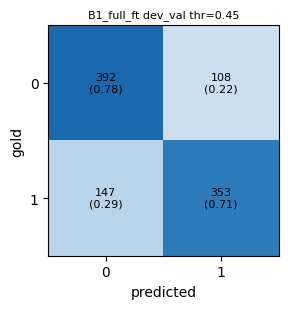

[B1_full_ft] dev_val macro-F1 @0.5=0.7357 | tuned(thr=0.45)=0.7446 | test_pos_rate=0.502 | /content/drive/MyDrive/Phase4_CJPE_GQLA/experiments/B1_full_ft/submission.zip


{'name': 'B1_full_ft',
 'technique': 'full fine-tuning',
 'trainable_params': 87705858,
 'total_params': 87705858,
 'n_layers': 10,
 'view': 'T0,T1',
 'pool': 'concat',
 'train_sec': 10843,
 'devval_infer_sec': 73.0,
 'peak_gb': 4.1,
 'best_epoch': 5,
 'test_pos_rate': 0.502,
 'notes': '',
 'time': '2026-10-20 07:20',
 'devval_F1@0.5': 0.7357,
 'devval_F1_tuned': 0.7446,
 'thr': 0.45,
 'P': 0.7465,
 'R': 0.745,
 'acc': 0.745,
 'F1_c0': 0.7546,
 'F1_c1': 0.7347}

In [ ]:
# B1) full fine-tuning (kept in memory as KD teacher)
run("B1_full_ft", "full fine-tuning", {"method": "full", **REP}, keep=True)

[B2_partial_top3] method=partial view=T0,T1 pool=concat trainable=21.70M / total=87.71M | AMP=True
{"epoch": 1, "train_loss": 0.6679, "sec": 1070.8, "skipped_nonfinite": 0, "dev_F1@0.5": 0.5877, "dev_F1_tuned": 0.6493, "thr": 0.42, "dev_acc": 0.605}
{"epoch": 2, "train_loss": 0.5866, "sec": 1066.5, "skipped_nonfinite": 0, "dev_F1@0.5": 0.677, "dev_F1_tuned": 0.6929, "thr": 0.53, "dev_acc": 0.68}
{"epoch": 3, "train_loss": 0.5681, "sec": 1067.8, "skipped_nonfinite": 0, "dev_F1@0.5": 0.6797, "dev_F1_tuned": 0.7116, "thr": 0.37, "dev_acc": 0.6833}
{"epoch": 4, "train_loss": 0.5561, "sec": 1068.9, "skipped_nonfinite": 0, "dev_F1@0.5": 0.7195, "dev_F1_tuned": 0.7216, "thr": 0.47, "dev_acc": 0.72}
{"epoch": 5, "train_loss": 0.5404, "sec": 1071.9, "skipped_nonfinite": 0, "dev_F1@0.5": 0.7147, "dev_F1_tuned": 0.7244, "thr": 0.38, "dev_acc": 0.715}


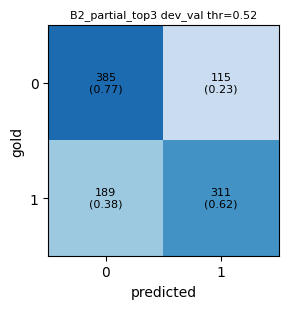

[B2_partial_top3] dev_val macro-F1 @0.5=0.6913 | tuned(thr=0.52)=0.6943 | test_pos_rate=0.459 | /content/drive/MyDrive/Phase4_CJPE_GQLA/experiments/B2_partial_top3/submission.zip


{'name': 'B2_partial_top3',
 'technique': 'partial fine-tuning (top 3 blocks)',
 'trainable_params': 21695234,
 'total_params': 87705858,
 'n_layers': 10,
 'view': 'T0,T1',
 'pool': 'concat',
 'train_sec': 5566,
 'devval_infer_sec': 73.0,
 'peak_gb': 3.85,
 'best_epoch': 5,
 'test_pos_rate': 0.459,
 'notes': '',
 'time': '2026-10-20 09:45',
 'devval_F1@0.5': 0.6913,
 'devval_F1_tuned': 0.6943,
 'thr': 0.52,
 'P': 0.7004,
 'R': 0.696,
 'acc': 0.696,
 'F1_c0': 0.7169,
 'F1_c1': 0.6717}

In [ ]:
# B2) partial fine-tuning: top-3 blocks + final LayerNorm (frozen lower blocks run under no_grad -> much cheaper)
run("B2_partial_top3", "partial fine-tuning (top 3 blocks)", {"method": "partial", "unfreeze_top": 3, **REP})

[B3_lorma] method=lorma view=T0,T1 pool=concat trainable=2.49M / total=89.61M | AMP=True
{"epoch": 1, "train_loss": 0.697, "sec": 2243.7, "skipped_nonfinite": 0, "dev_F1@0.5": 0.4998, "dev_F1_tuned": 0.4998, "thr": 0.5, "dev_acc": 0.5}
{"epoch": 2, "train_loss": 0.6924, "sec": 2231.0, "skipped_nonfinite": 0, "dev_F1@0.5": 0.4744, "dev_F1_tuned": 0.4744, "thr": 0.5, "dev_acc": 0.4933}
{"epoch": 3, "train_loss": 0.6954, "sec": 2227.8, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 2230.3, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
early stop


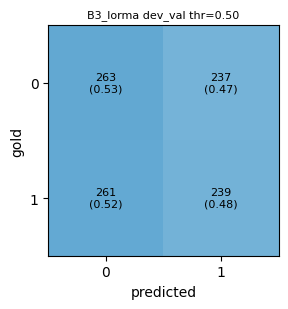

[B3_lorma] dev_val macro-F1 @0.5=0.5017 | tuned(thr=0.50)=0.5017 | test_pos_rate=0.46 | /content/drive/MyDrive/Phase4_CJPE_GQLA/experiments/B3_lorma/submission.zip


{'name': 'B3_lorma',
 'technique': 'LoRMA+ (multiplicative low-rank, additive inflation)',
 'trainable_params': 2493698,
 'total_params': 89605378,
 'n_layers': 10,
 'view': 'T0,T1',
 'pool': 'concat',
 'train_sec': 9125,
 'devval_infer_sec': 79.9,
 'peak_gb': 3.68,
 'best_epoch': 1,
 'test_pos_rate': 0.46,
 'notes': '',
 'time': '2026-10-20 12:21',
 'devval_F1@0.5': 0.5017,
 'devval_F1_tuned': 0.5017,
 'thr': 0.5,
 'P': 0.502,
 'R': 0.502,
 'acc': 0.502,
 'F1_c0': 0.5137,
 'F1_c1': 0.4898}

In [ ]:
# B3) LoRMA+ (compulsory)  -- PEFT usually needs a higher LR; if loss is flat after epoch 1, raise lr_adapter to 1e-3
run("B3_lorma", "LoRMA+ (multiplicative low-rank, additive inflation)", {"method": "lorma", **REP})

[B4_adapter] method=adapter view=T0,T1 pool=concat trainable=1.92M / total=89.03M | AMP=True
{"epoch": 1, "train_loss": 0.6731, "sec": 1989.0, "skipped_nonfinite": 0, "dev_F1@0.5": 0.4881, "dev_F1_tuned": 0.6048, "thr": 0.38, "dev_acc": 0.5633}
{"epoch": 2, "train_loss": 0.6175, "sec": 1981.6, "skipped_nonfinite": 0, "dev_F1@0.5": 0.6508, "dev_F1_tuned": 0.6556, "thr": 0.49, "dev_acc": 0.6567}
{"epoch": 3, "train_loss": 0.5941, "sec": 1982.4, "skipped_nonfinite": 0, "dev_F1@0.5": 0.6319, "dev_F1_tuned": 0.6878, "thr": 0.33, "dev_acc": 0.645}
{"epoch": 4, "train_loss": 0.5689, "sec": 1985.4, "skipped_nonfinite": 0, "dev_F1@0.5": 0.7116, "dev_F1_tuned": 0.7193, "thr": 0.42, "dev_acc": 0.7117}
{"epoch": 5, "train_loss": 0.5481, "sec": 1993.2, "skipped_nonfinite": 0, "dev_F1@0.5": 0.7181, "dev_F1_tuned": 0.7267, "thr": 0.39, "dev_acc": 0.7183}


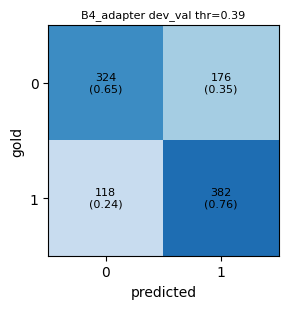

[B4_adapter] dev_val macro-F1 @0.5=0.6950 | tuned(thr=0.39)=0.7050 | test_pos_rate=0.56 | /content/drive/MyDrive/Phase4_CJPE_GQLA/experiments/B4_adapter/submission.zip


{'name': 'B4_adapter',
 'technique': 'Houlsby bottleneck adapters (dim 64)',
 'trainable_params': 1916418,
 'total_params': 89028098,
 'n_layers': 10,
 'view': 'T0,T1',
 'pool': 'concat',
 'train_sec': 10153,
 'devval_infer_sec': 73.6,
 'peak_gb': 3.67,
 'best_epoch': 5,
 'test_pos_rate': 0.56,
 'notes': '',
 'time': '2026-10-20 15:13',
 'devval_F1@0.5': 0.695,
 'devval_F1_tuned': 0.705,
 'thr': 0.39,
 'P': 0.7088,
 'R': 0.706,
 'acc': 0.706,
 'F1_c0': 0.6879,
 'F1_c1': 0.7221}

In [ ]:
# B4) Houlsby bottleneck adapters (after W_O and FFN-out)
run("B4_adapter", "Houlsby bottleneck adapters (dim 64)", {"method": "adapter", **REP})

[B5_bitfit] method=bitfit view=T0,T1 pool=concat trainable=0.63M / total=87.71M | AMP=True
{"epoch": 1, "train_loss": 0.6931, "sec": 2051.7, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.48, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6928, "sec": 2043.6, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6818, "sec": 2044.4, "skipped_nonfinite": 0, "dev_F1@0.5": 0.5034, "dev_F1_tuned": 0.572, "thr": 0.44, "dev_acc": 0.5683}
{"epoch": 4, "train_loss": 0.6381, "sec": 2049.9, "skipped_nonfinite": 0, "dev_F1@0.5": 0.5931, "dev_F1_tuned": 0.6075, "thr": 0.47, "dev_acc": 0.6}
{"epoch": 5, "train_loss": 0.6188, "sec": 2056.5, "skipped_nonfinite": 0, "dev_F1@0.5": 0.5581, "dev_F1_tuned": 0.6182, "thr": 0.39, "dev_acc": 0.5883}


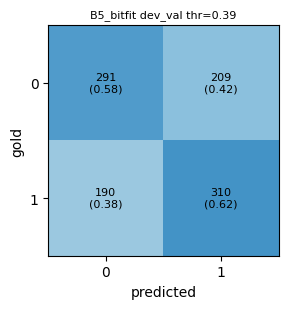

[B5_bitfit] dev_val macro-F1 @0.5=0.5527 | tuned(thr=0.39)=0.6009 | test_pos_rate=0.523 | /content/drive/MyDrive/Phase4_CJPE_GQLA/experiments/B5_bitfit/submission.zip


{'name': 'B5_bitfit',
 'technique': 'BitFit (biases only)',
 'trainable_params': 630530,
 'total_params': 87705858,
 'n_layers': 10,
 'view': 'T0,T1',
 'pool': 'concat',
 'train_sec': 10466,
 'devval_infer_sec': 72.9,
 'peak_gb': 3.66,
 'best_epoch': 5,
 'test_pos_rate': 0.523,
 'notes': '',
 'time': '2026-10-20 18:10',
 'devval_F1@0.5': 0.5527,
 'devval_F1_tuned': 0.6009,
 'thr': 0.39,
 'P': 0.6011,
 'R': 0.601,
 'acc': 0.601,
 'F1_c0': 0.5933,
 'F1_c1': 0.6084}

In [ ]:
# B5) true BitFit (FFN biases + all LayerNorm biases) -- GQLA has real biases, unlike the enc-dec model
run("B5_bitfit", "BitFit (biases only)", {"method": "bitfit", "lr_adapter": 1e-3, **REP})

[B6_kd_student] method=full view=T0,T1 pool=concat trainable=52.54M / total=52.54M | AMP=True
{"epoch": 1, "train_loss": 0.5546, "sec": 1629.4, "skipped_nonfinite": 0, "dev_F1@0.5": 0.5939, "dev_F1_tuned": 0.6377, "thr": 0.34, "dev_acc": 0.605}
{"epoch": 2, "train_loss": 0.4198, "sec": 1625.1, "skipped_nonfinite": 0, "dev_F1@0.5": 0.691, "dev_F1_tuned": 0.7116, "thr": 0.53, "dev_acc": 0.6933}
{"epoch": 3, "train_loss": 0.3904, "sec": 1624.9, "skipped_nonfinite": 0, "dev_F1@0.5": 0.6859, "dev_F1_tuned": 0.7185, "thr": 0.29, "dev_acc": 0.6917}
{"epoch": 4, "train_loss": 0.362, "sec": 1628.0, "skipped_nonfinite": 0, "dev_F1@0.5": 0.6958, "dev_F1_tuned": 0.7148, "thr": 0.47, "dev_acc": 0.6967}
{"epoch": 5, "train_loss": 0.3488, "sec": 1634.3, "skipped_nonfinite": 0, "dev_F1@0.5": 0.708, "dev_F1_tuned": 0.7149, "thr": 0.44, "dev_acc": 0.7083}


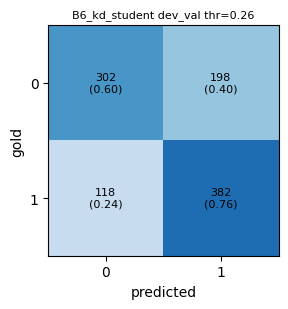

[B6_kd_student] dev_val macro-F1 @0.5=0.6637 | tuned(thr=0.26)=0.6820 | test_pos_rate=0.609 | /content/drive/MyDrive/Phase4_CJPE_GQLA/experiments/B6_kd_student/submission.zip
[B6b_student_no_kd] method=full view=T0,T1 pool=concat trainable=52.54M / total=52.54M | AMP=True
{"epoch": 1, "train_loss": 0.6943, "sec": 1072.3, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.49, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6924, "sec": 1067.9, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6954, "sec": 1067.2, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 1070.7, "skipped_nonfinite": 0, "dev_F1@0.5": 0.349, "dev_F1_tuned": 0.5104, "thr": 0.51, "dev_acc": 0.515}
{"epoch": 5, "train_loss": 0.6925, "sec": 1074.4, "skipped_nonfinite": 0, "dev_F1@0.5": 0.4468, "dev_F1_tuned": 0.4468, "th

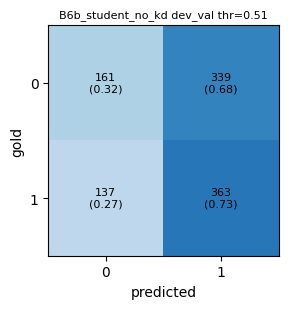

[B6b_student_no_kd] dev_val macro-F1 @0.5=0.3386 | tuned(thr=0.51)=0.5038 | test_pos_rate=0.684 | /content/drive/MyDrive/Phase4_CJPE_GQLA/experiments/B6b_student_no_kd/submission.zip


{'name': 'B6b_student_no_kd',
 'technique': '5-block student, hard labels only (KD ablation)',
 'trainable_params': 52539138,
 'total_params': 52539138,
 'n_layers': 5,
 'view': 'T0,T1',
 'pool': 'concat',
 'train_sec': 5464,
 'devval_infer_sec': 36.8,
 'peak_gb': 3.97,
 'best_epoch': 4,
 'test_pos_rate': 0.684,
 'notes': '',
 'time': '2026-10-20 22:02',
 'devval_F1@0.5': 0.3386,
 'devval_F1_tuned': 0.5038,
 'thr': 0.51,
 'P': 0.5287,
 'R': 0.524,
 'acc': 0.524,
 'F1_c0': 0.4035,
 'F1_c1': 0.604}

In [ ]:
# B6) knowledge distillation: teacher = B1 (10 blocks) -> student = bottom-5 Phase-1 blocks. Loss = CE + KL(logits) + cosine(window features)
teacher = MODELS["B1_full_ft"]
run("B6_kd_student", "KD: 10-block teacher -> 5-block student", {"method": "full", **REP}, n_layers=5, teacher=teacher, notes="teacher=B1_full_ft")
run("B6b_student_no_kd", "5-block student, hard labels only (KD ablation)", {"method": "full", **REP}, n_layers=5)

[X1_gradual] method=gradual view=T0,T1 pool=concat trainable=70.93M / total=87.71M | AMP=True
{"epoch": 1, "train_loss": 0.6945, "sec": 620.0, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3396, "dev_F1_tuned": 0.3396, "thr": 0.5, "dev_acc": 0.4733}
{"epoch": 2, "train_loss": 0.6923, "sec": 918.0, "skipped_nonfinite": 0, "dev_F1@0.5": 0.481, "dev_F1_tuned": 0.481, "thr": 0.5, "dev_acc": 0.5433}
{"epoch": 3, "train_loss": 0.6357, "sec": 1216.0, "skipped_nonfinite": 0, "dev_F1@0.5": 0.5252, "dev_F1_tuned": 0.6766, "thr": 0.24, "dev_acc": 0.5833}
{"epoch": 4, "train_loss": 0.5896, "sec": 1517.4, "skipped_nonfinite": 0, "dev_F1@0.5": 0.6854, "dev_F1_tuned": 0.7083, "thr": 0.57, "dev_acc": 0.6917}
{"epoch": 5, "train_loss": 0.5572, "sec": 1823.1, "skipped_nonfinite": 0, "dev_F1@0.5": 0.7236, "dev_F1_tuned": 0.7395, "thr": 0.47, "dev_acc": 0.725}
{"epoch": 6, "train_loss": 0.5271, "sec": 2116.1, "skipped_nonfinite": 0, "dev_F1@0.5": 0.7122, "dev_F1_tuned": 0.7299, "thr": 0.46, "dev_acc": 0.7133}


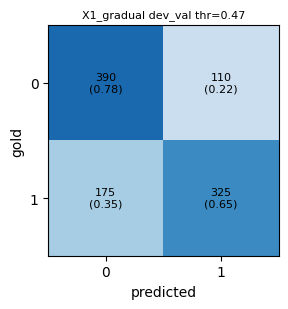

[X1_gradual] dev_val macro-F1 @0.5=0.7012 | tuned(thr=0.47)=0.7138 | test_pos_rate=0.456 | /content/drive/MyDrive/Phase4_CJPE_GQLA/experiments/X1_gradual/submission.zip
[X2_lora] method=lora view=T0,T1 pool=concat trainable=2.21M / total=89.33M | AMP=True
{"epoch": 1, "train_loss": 0.6925, "sec": 2286.3, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.49, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6929, "sec": 2273.9, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6954, "sec": 2272.5, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 2276.0, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
early stop


In [ ]:
# Extras (optional, only if time remains): gradual unfreezing, LoRA, rsLoRA, IA3, prompt tuning
run("X1_gradual", "gradual layer-wise unfreezing (+2 blocks/epoch)", {"method": "gradual", "epochs": 6, "patience": 6, **REP})
run("X2_lora", "LoRA r=8", {"method": "lora", **REP})
run("X3_rslora", "rsLoRA r=16", {"method": "rslora", "r": 16, **REP})
run("X4_ia3", "IA3 (K, V, FFN hidden)", {"method": "ia3", "lr_adapter": 1e-3, **REP})
run("X5_prompt", "prompt tuning (16 soft tokens)", {"method": "prompt", "lr_adapter": 1e-3, **REP})

### Part A – which windows matter? (representation study; use a cheap method such as partial FT with a small budget, e.g. `docs_per_epoch=4000, epochs=3`)

In [ ]:
cheap = {"method": "partial", "unfreeze_top": 3, "docs_per_epoch": 4000, "epochs": 3}
for nm, v, w, pl in [("A1_T0", "T0", 512, "last"), ("A2_T0T1", "T0,T1", 512, "concat"), ("A3_T0T1T2", "T0,T1,T2", 512, "concat"),
                     ("A4_H0T0", "H0,T0", 512, "concat"), ("A5_T0_256", "T0", 256, "last")]:
    run(nm, f"view study | {v} | win {w} | pool {pl} (partial FT)", {**cheap, "view": v, "win_len": w, "pool": pl})

## 10. Error analysis hooks and summary

In [ ]:
def error_by_length(name, q=4):
    df = pd.read_csv(os.path.join(OUTPUT_DIR, "experiments", name, "dev_val_preds.csv")); df["len_bin"] = pd.qcut(df["n_tok"], q, duplicates="drop")
    f = lambda g: pd.Series({"n": len(g), "acc": (g.y == g.pred).mean(), "FP": ((g.y == 0) & (g.pred == 1)).sum(), "FN": ((g.y == 1) & (g.pred == 0)).sum(), "frac_1": g.y.mean()})
    return df.groupby("len_bin", observed=True).apply(f).round(3)
reg = pd.DataFrame(registry)
cols = [c for c in ["name", "technique", "trainable_params", "total_params", "devval_F1@0.5", "devval_F1_tuned", "thr", "P", "R", "F1_c0", "F1_c1", "train_sec", "devval_infer_sec", "peak_gb", "test_pos_rate", "view"] if c in reg.columns]
reg[cols]

## Notes / limitations (put these in your report, in your own words)
* `devval_F1_tuned` uses a threshold fitted on the same `dev_val` it is reported on, so it is mildly optimistic; `devval_F1@0.5` is the stricter number. `dev_val` (1 000 docs) is small: differences of ~1–2 points are noise.
* Dev docs (other than the hold-out) are used for training, repeated `DEV_REPEAT`×. Test never touches training or threshold selection.
* Documents are trimmed to first 2 048 + last 6 144 tokens; windows beyond the chosen `view` are never seen. Report this.
* fp16 autocast is enabled only if `check_amp()` passes; otherwise runs in fp32 (slower).
* Cite: Hu et al. 2021 (LoRA), Kalajdzievski 2023 (rsLoRA), Bihany et al. 2025 (LoRMA), Houlsby et al. 2019, Ben Zaken et al. 2022 (BitFit), Liu et al. 2022 (IA³), Lester et al. 2021, Hinton et al. 2015, Chen et al. 2016 (checkpointing), Malik et al. 2021 (ILDC), and the GQLA paper you implemented in Phase 1.